# All project figures

Run from the `results/` folder. **Run the setup and function cells first (Parts 0A to 0D)**; after that, each section of Parts I and II can be run independently.

| Part | Content | Output |
|---|---|---|
| **0A** | Setup and functions for full-shot | — |
| **0B** | Setup and functions for few-shot | — |
| **0C** | Pipeline cost: feature extraction vs TabPFN (fit + predict); fit and predict time | — |
| **0D** | Dataset properties: where does performance change? | — |
| **I** | Full-shot: Redux (univariate) and UEA (multivariate) — CD of the TabPFN variants and against baselines; VRAM and time; 2.5 × 3.5 accuracy; scaling; pipeline cost; dataset properties | `figs/full/*.pdf` |
| **II** | Few-shot: Redux and UEA — CD at K = 10; class coverage; cost table, accuracy × cost trade-off and pipeline cost; comparison with the literature (CD); sample efficiency; dataset properties; Ridge and 1NN baselines on the same support sets (accuracy vs K, selection by model, gap to the oracle, coverage, sample efficiency, scatter, CD against the literature) | `figs/few/*.pdf` |

The two sides are independent (each has its own functions and output directory), so function names do not collide: `save_full`/`save_few`, `FIG_FULL`/`FIG_FEW`.

# Part 0 — Setup and functions

Settings, loaders and plotting functions (no figures). Run every cell of this part before Parts I and II; fold this heading to hide it.

## Part 0A — Setup and functions (full-shot)

### CodeCarbon overhead in the time plots

The TabPFN logs time each stage (`fit`, `predict`, `predict_proba`) around a CodeCarbon `EmissionsTracker` start/stop, so every logged time carries a fixed overhead. It was measured by running an empty tracked block with the same settings as `utils/utils_train.py`: **3.09 s** per block (median of 9 repeated calls, 3.08–3.12 s, almost all of it in `stop()`); the first call of a process takes about 4.3 s, which is not corrected.

What the notebook does with it (`CODECARBON_OVERHEAD_S`, set in the first setup cell; `CORRECT_CODECARBON = False` shows the raw logged times):

- **Inference time** (predict step): 3.09 s is subtracted from the per-dataset times when the CSV is read (`_read`, for files in an `inference_time` folder). This affects the inference-time distribution, the time vs number of training examples panel, and the time ratio of the accuracy × cost trade-off plot.
- **Pipeline cost** (TabPFN fit + predict segment): 3.09 s is subtracted from the median train time and from the median predict time of each dataset (`_stages`) before they are added. Values are floored at zero.
- **Not corrected:** energy (the overhead lies outside the measured window), VRAM (measured by the GPU monitor), and feature-extraction time (timed inside the tracker). The baselines (Ridge, 1NN) were not tracked.

Figures affected: inference-time distribution, time vs number of training examples (left panel), pipeline cost and fit/predict time (time panels, full-shot and few-shot) and the trade-off (inference-time panel), in both benchmarks.

In [1]:
import glob
import os
import re
import zipfile
from functools import lru_cache
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter, NullFormatter
from scipy.stats import spearmanr, wilcoxon
from aeon.visualisation import plot_critical_difference

# ---------------- Configuration ----------------
FIG_FULL = Path("./figs/full")
FIG_FULL.mkdir(parents=True, exist_ok=True)
SHOW_TITLES = False               # figure titles go in the LaTeX caption; set True to inspect the figures

# CodeCarbon start/stop adds a fixed overhead to every tracked block (fit, predict, predict_proba): measured at 3.09 s
# (median of 9 repeated calls, range 3.08-3.12 s; the first call of a process takes about 4.3 s). It is subtracted from
# the TabPFN train and predict (= inference) times below. Energy is not corrected: the overhead falls outside the
# measured window (an empty tracked block reports ~1e-7 kWh). Feature-extraction time is timed inside the tracker.
CORRECT_CODECARBON = True         # False: show the raw logged times
CODECARBON_OVERHEAD_S = 3.09 if CORRECT_CODECARBON else 0.0

# ---------------- Figure style (thesis) ----------------
mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Nimbus Roman", "Liberation Serif", "STIXGeneral"],
    "mathtext.fontset": "stix",
    "font.size": 10, "axes.labelsize": 10, "axes.titlesize": 10,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": True, "legend.framealpha": 0.92, "legend.facecolor": "white",   # boxed legends stay readable over the points
    "legend.edgecolor": "0.6", "legend.fancybox": False, "legend.borderpad": 0.5,
    "figure.dpi": 120, "savefig.dpi": 300, "savefig.bbox": "tight",
    "pdf.fonttype": 42, "ps.fonttype": 42,        # embed fonts as TrueType (accepted by publishers)
})


def fig_title(fig, s, note_prefix="", **kw):
    """Figure title. In print mode only a small 'n = ... datasets' note is kept (the caption carries the rest);
    `note_prefix` (e.g. the selection method) goes before it."""
    if SHOW_TITLES:
        fig.suptitle(s, **kw)
        return
    m = re.search(r"(?:K ?= ?\d+, )?n ?= ?\d+ datasets", s)
    note = (note_prefix + (m.group(0).replace("K=", "K = ").replace("n=", "n = ") if m else "")).rstrip(", ")
    if note:
        fig.text(0.995, 0.995, note, ha="right", va="top", fontsize=8, color="0.35")


def boot_ci(v, n_boot=4000, seed=0, q=(2.5, 97.5)):
    """Mean and 95% bootstrap (percentile) CI over the elements of v (datasets)."""
    v = np.asarray(v, float)
    rng = np.random.default_rng(seed)
    means = v[rng.integers(0, len(v), (n_boot, len(v)))].mean(axis=1)
    return v.mean(), *np.percentile(means, q)

VERSIONS = ["2.5", "3.5"]
FEATURES = ["c22", "tsfresh", "multirocket"]
VCOLORS = {"2.5": "#4C78A8", "3.5": "#F58518"}          # color = TabPFN version
FMARKERS = {"c22": "o", "tsfresh": "s", "multirocket": "^"}   # marker = feature extractor
TOP_N = 10        # number of literature baselines shown in the comparisons (full-shot CD and few-shot vs full-shot)
MIN_COV = 0.8     # a baseline is only included if it covers >= 80% of the reference datasets (the redux ones cover 86%)

BENCHMARKS = {
    "redux": {
        "label": "univariate (redux)",
        "tabpfn_dir": Path("./full/redux"), "base_dir": Path("./full/redux"),
        "ref": None,
        "baselines": ["FreshPRINCE", "HC2", "H-InceptionTime", "MR-Hydra", "PF", "QUANT", "RDST", "WEASEL-2"],
    },
    "uea": {
        "label": "multivariate (UEA)",
        "tabpfn_dir": Path("./full/mv_core"), "base_dir": Path("./full/uea"),
        "ref": Path("./full/uea/accuracy/1NN-DTW-D_accuracy.csv"),
        "baselines": ["1NN-DTW-A", "1NN-DTW-D", "1NN-DTW-I", "Arsenal", "cBOSS", "CIF", "DrCIF", "HC1", "HC2",
                      "InceptionT", "MrSEQL", "MUSE", "ResNet", "RISE", "ROCKET", "RSF", "STC", "TapNet", "TDE", "TSF"],
    },
}

STATS = {
    "vram_total_mb": dict(
        ylabel="Total VRAM per dataset (MB, log scale)", title="VRAM usage distribution", fmt="{:.0f}",
        unit="MB", label="Total VRAM (MB)", head="VRAM usage",
        scatter="Per-dataset comparison\n(below the diagonal = 3.5 uses less VRAM)"),
    "inference_time": dict(
        ylabel="Time per dataset (s, log scale)", title="Time distribution", fmt="{:.1f}s",
        unit="s", label="Inference time (s)", head="Inference time",
        scatter="Per-dataset comparison\n(below the diagonal = 3.5 faster)"),
}


def save_full(fig, name):
    fig.savefig(FIG_FULL / f"{name}.pdf")


# ---------------- Loading ----------------
def _read(path):
    """Results CSV -> DataFrame (datasets x resample ids)."""
    df = pd.read_csv(path, index_col=0)
    df.index = df.index.astype(str).str.replace(r"_(eq|nmv)$", "", regex=True)   # bake-off files keep the _eq/_nmv suffix
    df = df.select_dtypes(include="number")
    df.columns = [int(c) for c in df.columns]
    if Path(path).parent.name == "inference_time":              # inference time = predict_time, one CodeCarbon-tracked block
        df = (df - CODECARBON_OVERHEAD_S).clip(lower=0)
    return df


def score(path):
    """Per-dataset accuracy: mean over the resamples."""
    return _read(path).mean(axis=1)


def ref_datasets(cfg):
    """Reference-benchmark datasets (UEA: those that 1NN-DTW-D ran on); None = no filter."""
    return None if cfg["ref"] is None else _read(cfg["ref"]).mean(axis=1).dropna().index


def combine(scores, ref):
    df = pd.DataFrame(scores)
    if ref is not None:
        df = df.loc[df.index.intersection(ref)]
    return df.dropna()


def tabpfn_scores(cfg):
    return {f"{f}-TabPFN{v}": score(cfg["tabpfn_dir"] / "accuracy" / f"TabPFN{v}-{f}_accuracy.csv")
            for v in ["3.5", "2.5"] for f in FEATURES}


def load_cost(bench, stat):
    """{(version, feature): per-dataset Series} (mean over runs), filtered to the reference benchmark."""
    cfg = BENCHMARKS[bench]
    ref = ref_datasets(cfg)
    data = {}
    for v in VERSIONS:
        for f in FEATURES:
            p = cfg["tabpfn_dir"] / stat / f"TabPFN{v}-{f}_{stat}.csv"
            if not p.exists():
                print(f"Not found: {p}")
                continue
            s = _read(p).mean(axis=1)
            data[v, f] = s.reindex(ref).dropna() if ref is not None else s
    return data

### Functions: critical-difference diagrams

`cd_tabpfn` compares only the 6 TabPFN variants; `cd_vs_baselines` compares the best 2 TabPFN variants (by mean rank) with the best `TOP_N` baselines (by mean accuracy, among those covering >= `MIN_COV` of the reference datasets — the others are listed and excluded). Blue/orange: TabPFN 2.5/3.5.

In [2]:
def draw_cd(df, name, title):
    hl = {c: VCOLORS[c[-3:]] for c in df.columns if "TabPFN" in c}
    fig, _ = plot_critical_difference(df.to_numpy(), df.columns.tolist(), test="wilcoxon", alpha=0.05, highlight=hl)
    fig_title(fig, f"{title} (n = {len(df)} datasets)", y=1.08)
    save_full(fig, name)
    plt.show()


def cd_tabpfn(bench):
    cfg = BENCHMARKS[bench]
    df = combine(tabpfn_scores(cfg), ref_datasets(cfg))
    print(f"[{bench}] datasets used: {len(df)}")
    draw_cd(df, f"cd_tabpfn_{bench}", f"TabPFN variants — {cfg['label']}")


def baseline_cd_table(bench, top_n=TOP_N, min_cov=MIN_COV, n_tabpfn=None):
    """Accuracy table (datasets x classifiers) used by the CD diagram vs baselines.
    `n_tabpfn`: keep only that many TabPFN variants (the ones with the best mean rank among the six); None keeps all six.
    Returns (table, kept baselines, excluded baselines, number of candidate baselines)."""
    cfg = BENCHMARKS[bench]
    ref = ref_datasets(cfg)
    tab = tabpfn_scores(cfg)
    idx = combine(tab, ref).index                       # datasets where all TabPFN variants exist
    base, cov = {}, {}
    for n in cfg["baselines"]:
        p = cfg["base_dir"] / "accuracy" / f"{n}_accuracy.csv"
        if p.exists():
            base[n] = score(p)
            cov[n] = base[n].reindex(idx).notna().mean()
    ok = {n: base[n].reindex(idx).mean() for n in base if cov[n] >= min_cov}
    top = sorted(ok, key=ok.get, reverse=True)[:top_n]
    excl = [f"{n} ({100 * cov[n]:.0f}%)" for n in base if cov[n] < min_cov]
    df = combine({**{n: base[n] for n in top}, **tab}, ref)
    if n_tabpfn is not None:                             # best TabPFN variants, by mean rank among the six
        ranks = df[list(tab)].rank(axis=1, ascending=False).mean()
        df = df[top + list(ranks.nsmallest(n_tabpfn).index)]
    return df, top, excl, len(base)


def cd_vs_baselines(bench, top_n=TOP_N, min_cov=MIN_COV, n_tabpfn=2):
    cfg = BENCHMARKS[bench]
    df, top, excl, n_all = baseline_cd_table(bench, top_n, min_cov, n_tabpfn)
    print(f"[{bench}] datasets used: {len(df)} | baselines: {len(top)} of {n_all} | TabPFN variants: {[c for c in df.columns if 'TabPFN' in c]}")
    if excl:
        print("  excluded for low dataset coverage:", ", ".join(excl))
    draw_cd(df, f"cd_baselines_{bench}", f"TabPFN × baselines (top {len(top)}) — {cfg['label']}")


### Functions: VRAM and time

`plot_cost_dist` (boxplot per feature/version + per-dataset 2.5 × 3.5 scatter) serves the two cost metrics (VRAM and time); `plot_vram_breakdown` splits VRAM into fixed (model) and dynamic (data) cost.

In [3]:
def plot_cost_dist(bench, stat):
    cfg, st = BENCHMARKS[bench], STATS[stat]
    data = load_cost(bench, stat)
    ref = ref_datasets(cfg)

    summary = pd.DataFrame({
        f"TabPFN{v}-{f}": {"datasets": s.notna().sum(), f"median ({st['unit']})": s.median(),
                           f"mean ({st['unit']})": s.mean(), f"max ({st['unit']})": s.max(),
                           **({f"total ({st['unit']})": s.sum()} if stat == "inference_time" else {})}   # a sum of peak VRAM means nothing
        for (v, f), s in data.items()}).T
    print(summary.to_string(float_format=lambda x: f"{x:.4g}"))
    if ref is not None:
        print(f"\nDatasets in the benchmark: {len(ref)}")

    fig, (a, b) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.4, 1]})
    rng, w = np.random.default_rng(0), 0.32
    for j, v in enumerate(VERSIONS):
        for i, f in enumerate(FEATURES):
            s = data.get((v, f))
            if s is None:
                continue
            y = s.dropna().to_numpy()
            y = y[y > 0]
            if not len(y):
                continue
            pos = i + (j - (len(VERSIONS) - 1) / 2) * (w + .04)
            bp = a.boxplot(y, positions=[pos], widths=w, patch_artist=True, showfliers=False,
                           medianprops=dict(color=VCOLORS[v], lw=2))
            bp["boxes"][0].set(facecolor=VCOLORS[v], edgecolor=VCOLORS[v], alpha=.35)
            for obj in bp["whiskers"] + bp["caps"]:
                obj.set(color=VCOLORS[v])
            a.scatter(pos + rng.uniform(-w / 3, w / 3, len(y)), y, s=8, color=VCOLORS[v], alpha=.5, zorder=3)
            left = j == 0                                    # 2.5 label left of its box, 3.5 label right of its box
            a.annotate(st["fmt"].format(np.median(y)), (pos + (-1 if left else 1) * (w / 2 + .02), np.median(y)),
                       ha="right" if left else "left", va="center", fontsize=9, fontweight="bold", color=VCOLORS[v],
                       bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85), zorder=5)
    a.set(yscale="log", xticks=range(len(FEATURES)), xticklabels=FEATURES, ylabel=st["ylabel"], title=st["title"])
    a.set_xlim(-0.85, len(FEATURES) - 1 + 0.85)              # room for the median labels outside the boxes
    a.grid(axis="y", which="both", alpha=.25)
    a.set_axisbelow(True)
    a.legend(handles=[plt.Rectangle((0, 0), 1, 1, fc=VCOLORS[v], alpha=.5, label=f"TabPFN {v}") for v in VERSIONS],
             loc="upper left")

    markers, vals = ["o", "s", "^"], []
    for k, f in enumerate(FEATURES):
        sx, sy = data.get(("2.5", f)), data.get(("3.5", f))
        if sx is None or sy is None:
            continue
        pair = pd.concat([sx.rename("x"), sy.rename("y")], axis=1).dropna()
        pair = pair[(pair > 0).all(axis=1)]
        b.scatter(pair.x, pair.y, s=14, alpha=.6, marker=markers[k], label=f)
        vals.extend(pair.to_numpy().ravel())
    if vals:
        lo, hi = min(vals) * .8, max(vals) * 1.25
        b.plot([lo, hi], [lo, hi], "k--", lw=1, alpha=.6, label="y = x")
        b.set(xlim=(lo, hi), ylim=(lo, hi))
    b.set(xscale="log", yscale="log", xlabel=f"TabPFN 2.5 ({st['unit']})", ylabel=f"TabPFN 3.5 ({st['unit']})",
          title=st["scatter"])
    b.grid(which="both", alpha=.25)
    b.set_axisbelow(True)
    b.legend()
    fig_title(fig, f"{st['head']} — {cfg['label']}")
    plt.tight_layout()
    save_full(fig, f"{stat}_dist_{bench}")
    plt.show()


def plot_vram_breakdown(bench):
    cfg = BENCHMARKS[bench]
    model, dyn = load_cost(bench, "vram_model_mb"), load_cost(bench, "vram_data_mb")
    rows = [(f"{f}\nTabPFN {v}", model[v, f].mean(), dyn[v, f].mean())
            for f in FEATURES for v in VERSIONS if (v, f) in model and (v, f) in dyn]
    df = pd.DataFrame(rows, columns=["label", "model", "data"])
    df["total"] = df.model + df.data

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.bar(df.index, df.model, color="#4C78A8", label="Fixed cost")
    ax.bar(df.index, df.data, bottom=df.model, color="#F58518", label="Dynamic cost (peak during inference)")
    for i, r in df.iterrows():
        ax.text(i, r.total, f"Dynamic: {100 * r.data / r.total:.1f}%", ha="center", va="bottom", fontsize=9)
    ax.set_xticks(df.index)
    ax.set_xticklabels(df.label)
    ax.set_ylim(0, df.total.max() * 1.1)
    ax.set_ylabel("Mean VRAM (MB)")
    fig_title(fig, f"Total VRAM = model + data — {cfg['label']}")
    ax.legend(loc="upper left")
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
    plt.tight_layout()
    save_full(fig, f"vram_breakdown_{bench}")
    plt.show()

### Functions: 2.5 vs 3.5 accuracy and scaling

- **`plot_acc_2v3`** — per-dataset accuracy, TabPFN 2.5 × 3.5, for each feature extractor, with the wins/ties/losses of 3.5, mean difference (percentage points) and Wilcoxon p-value.
- **`plot_scaling`** — time and VRAM against training-set size (log-log scale), with the Spearman correlation.

All of them use the mean over runs and only the datasets where the 6 variants have results (on UEA, still restricted to the reference datasets).

In [4]:
def acc_table(bench):
    """Mean accuracy per dataset for the 6 variants (columns '<version>-<feature>'), complete datasets only."""
    cfg = BENCHMARKS[bench]
    sc = {f"{v}-{f}": score(cfg["tabpfn_dir"] / "accuracy" / f"TabPFN{v}-{f}_accuracy.csv")
          for v in VERSIONS for f in FEATURES}
    return combine(sc, ref_datasets(cfg))


def plot_acc_2v3(bench):
    cfg, A = BENCHMARKS[bench], acc_table(bench)
    fig, axes = plt.subplots(1, len(FEATURES), figsize=(4.3 * len(FEATURES), 4.4), sharex=True, sharey=True)
    lo = min(A.min()) - 0.02
    for ax, f in zip(axes, FEATURES):
        x, y = A[f"2.5-{f}"], A[f"3.5-{f}"]
        d = y - x
        try:
            p = wilcoxon(y, x).pvalue
        except ValueError:
            p = np.nan
        ax.scatter(x, y, s=16, alpha=.65, color=VCOLORS["3.5"])
        ax.plot([lo, 1], [lo, 1], "k--", lw=1, alpha=.6)
        ax.set_title(f"{f}\nW/T/L (3.5) = {int((d > 0).sum())}/{int((d == 0).sum())}/{int((d < 0).sum())}"
                     f"  |  Δ = {100 * d.mean():+.2f} p.p.  |  p {'< 0.001' if p < 0.001 else f'= {p:.3f}'}", fontsize=10)
        ax.set_xlabel("Accuracy — TabPFN 2.5")
        ax.set_xlim(lo, 1.01)
        ax.set_ylim(lo, 1.01)
        ax.grid(alpha=.3)
        ax.set_axisbelow(True)
    axes[0].set_ylabel("Accuracy — TabPFN 3.5")
    fig_title(fig, f"TabPFN 2.5 × 3.5 — {cfg['label']} (n = {len(A)} datasets; above the diagonal = 3.5 better)")
    plt.tight_layout()
    save_full(fig, f"acc_2v3_{bench}")
    plt.show()


def n_train_by_dataset():
    """Number of training examples per dataset, from the GPU logs (same for any feature/version)."""
    files = glob.glob("../outputs/full/3.5/*/gpu/*.csv")
    return pd.concat([pd.read_csv(f) for f in files]).groupby("dataset")["n_train_samples"].first()


def plot_scaling(bench, stats=("inference_time", "vram_total_mb")):
    cfg = BENCHMARKS[bench]
    n_train = n_train_by_dataset()
    fig, axes = plt.subplots(1, len(stats), figsize=(6.2 * len(stats), 4.8))
    for ax, stat in zip(axes, stats):
        data, rho = load_cost(bench, stat), {}
        for v in VERSIONS:
            for f in FEATURES:
                s = data[v, f]
                n = n_train.reindex(s.index)
                ok = n.notna() & (s > 0)
                ax.scatter(n[ok], s[ok], s=14, alpha=.55, color=VCOLORS[v], marker=FMARKERS[f])
                rho[v, f] = spearmanr(n[ok], s[ok])[0]
        ax.set(xscale="log", yscale="log", xlabel="Number of training examples", ylabel=STATS[stat]["label"])
        ax.grid(alpha=.3, which="both")
        ax.set_axisbelow(True)
        print(f"[{bench}] Spearman ({stat} × n_train): " +
              ", ".join(f"{v}-{f}={r:.2f}" for (v, f), r in rho.items()))
    hs = [plt.Line2D([], [], marker="o", ls="", color=VCOLORS[v], label=f"TabPFN {v}") for v in VERSIONS]
    hs += [plt.Line2D([], [], marker=FMARKERS[f], ls="", color="gray", label=f) for f in FEATURES]
    axes[0].legend(handles=hs, loc="upper left", fontsize=8)
    fig_title(fig, f"Scaling with training-set size — {cfg['label']}")
    plt.tight_layout()
    save_full(fig, f"scaling_{bench}")
    plt.show()

## Part 0B — Setup and functions (few-shot)

In [5]:
# (imports already done in Part 0A)
# ---------------- Configuration ----------------
TABPFN_VERSION = "3.5"

FEW_DIR = Path("./few")
FULL_DIR = Path("./full")
RAW_DIR = Path("../outputs/few")   # raw CSVs (they have class_coverage, n_support, n_pool)
FIG_FEW = Path("./figs/few")
FIG_FEW.mkdir(parents=True, exist_ok=True)

METHODS = ["random", "stratified_random", "kmedoids", "stratified_kmedoids"]
KS = [1, 3, 5, 10]
FEW_CFGS = tuple(("stratified_kmedoids", k) for k in KS)   # few-shot configs compared with full-shot (every K)
RUNS = [0, 1, 2]

BENCH_CFG = {
    "redux": {"feature": "multirocket", "full_dir": "redux"},
    "uea": {"feature": "tsfresh", "full_dir": "mv_core"},
}
LABELS = {
    "random": "Random",
    "stratified_random": "Stratified Random",
    "kmedoids": "KMedoids",
    "stratified_kmedoids": "Stratified KMedoids",
}
COLORS = {
    "random": "#9ecae1",
    "stratified_random": "#3182bd",
    "kmedoids": "#fdae6b",
    "stratified_kmedoids": "#e6550d",
}
COST_METRICS = {
    "inference_time": "Inference time (s)",
    "vram_total_mb": "Total VRAM (MB)",
    "vram_data_mb": "Data VRAM (MB)",
}


def save_few(fig, name, bench):
    fig.savefig(FIG_FEW / f"{name}_{bench}.pdf")


# ---------------- Loading (the CSV reader `_read` is in Part 0A) ----------------
def load_few(method, k, bench, metric="accuracy"):
    p = FEW_DIR / method / f"K_{k}" / bench / metric / f"TabPFN-few_{method}_K{k}_{metric}.csv"
    return _read(p).reindex(columns=RUNS)


def load_full(bench, metric="accuracy"):
    cfg = BENCH_CFG[bench]
    p = FULL_DIR / cfg["full_dir"] / metric / f"TabPFN{TABPFN_VERSION}-{cfg['feature']}_{metric}.csv"
    return _read(p).reindex(columns=RUNS)


def load_metric(bench, metric):
    """(few, full_mean): few has columns (method, K, run); full_mean is the mean over the available full-shot runs."""
    fr = {}
    for m in METHODS:
        for k in KS:
            try:
                fr[(m, k)] = load_few(m, k, bench, metric)
            except FileNotFoundError as e:
                print("Not found:", e)
    return pd.concat(fr, axis=1).sort_index(axis=1), load_full(bench, metric).mean(axis=1)


class Ctx:
    """Data of one benchmark: accuracy (few, full_mean) and cost metrics (cost)."""

    def __init__(self, bench):
        self.bench = bench
        self.few, self.full_mean = load_metric(bench, "accuracy")
        self.cost = {met: load_metric(bench, met) for met in COST_METRICS}
        print(f"[{bench}] datasets in few-shot: {len(self.few)} | valid in ALL methods/K: {len(self.valid())}")
        for k in KS:
            print(f"  K={k}: {len(self.valid([k]))} valid datasets")

    def valid(self, ks=KS, methods=METHODS):
        """Datasets without NaN for all requested (method, K), that also exist in full-shot."""
        mask = [(c[0] in methods) and (c[1] in ks) for c in self.few.columns]
        return self.few.loc[:, mask].dropna().index.intersection(self.full_mean.dropna().index)

    def valid_cost(self, metric, ks=KS, methods=METHODS):
        """Datasets valid in accuracy and without NaN in the cost metric."""
        f, full = self.cost[metric]
        mask = [(c[0] in methods) and (c[1] in ks) for c in f.columns]
        return self.valid(ks, methods).intersection(f.loc[:, mask].dropna().index).intersection(full.dropna().index)

    def cost_ratio(self, metric, m, k, ds):
        f, full = self.cost[metric]
        return f.loc[ds, (m, k)].mean(axis=1) / full[ds]


_CTX = {}


def ctx(bench, reload=False):
    """Load the benchmark data once; `reload=True` rereads the CSVs."""
    if reload or bench not in _CTX:
        _CTX[bench] = Ctx(bench)
    return _CTX[bench]

### Summary table (method × K)

In [6]:
def summary_table(bench):
    c = ctx(bench)
    rows = []
    for m in METHODS:
        for k in KS:
            ds = c.valid([k])
            per = c.few.loc[ds, (m, k)].mean(axis=1)
            rows.append({
                "method": LABELS[m], "K": k, "n datasets": len(ds),
                "mean acc": per.mean(), "acc / full-shot": (per / c.full_mean[ds]).mean(),
            })
    t = pd.DataFrame(rows).pivot(index="method", columns="K")
    return t.reindex([LABELS[m] for m in METHODS])

### 1. Critical-difference diagram (K = 10)

In [7]:
def plot_cd_per_k(bench, ks=(10,)):
    c = ctx(bench)
    for k in ks:
        ds = c.valid([k])
        tab = pd.DataFrame({LABELS[m]: c.few.loc[ds, (m, k)].mean(axis=1) for m in METHODS})
        fig, _ = plot_critical_difference(
            tab.to_numpy(), tab.columns.tolist(), test="wilcoxon", alpha=0.05
        )
        fig_title(fig, f"CD per selection method — {bench} (K={k}, n={len(ds)} datasets)", y=1.08)
        save_few(fig, f"cd_K{k}", bench)
        plt.show()

### 2. Class coverage vs relative accuracy (non-stratified methods)

Uses the raw CSVs from `outputs/few/...` (column `class_coverage`). Each point is one run; its accuracy is divided by the full-shot accuracy of the same dataset and resample, so dataset difficulty does not mix with the coverage effect.

In [8]:
def load_raw(bench, method, k):
    files = sorted(glob.glob(str(RAW_DIR / method / f"K_{k}" / f"results_{bench}_*.csv")))
    if not files:
        return None
    df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
    out = pd.DataFrame({
        "dataset": df["dataset"].astype(str),
        "run": df["run"],
        "acc": df["accuracy"],
        "coverage": df["class_coverage"],
        "K": k,
    })
    return out


def plot_coverage(bench, methods=("random", "kmedoids")):
    full = load_full(bench).stack()                        # full-shot accuracy per (dataset, resample)
    fig, axes = plt.subplots(1, len(methods), figsize=(5.5 * len(methods), 4.3), sharey=True)
    axes = np.atleast_1d(axes)
    cmap = plt.get_cmap("viridis")
    rng = np.random.default_rng(0)

    for ax, m in zip(axes, methods):
        raws = [r for r in (load_raw(bench, m, k) for k in KS) if r is not None]
        if not raws:
            print("No raw CSVs for", m)
            continue
        raw = pd.concat(raws)
        raw["rel"] = raw.acc.values / full.reindex(pd.MultiIndex.from_arrays([raw.dataset, raw.run])).values
        raw = raw.dropna(subset=["rel"])                     # same resample in few- and full-shot
        for i, k in enumerate(KS):
            r = raw[raw.K == k]
            ax.scatter(r.coverage + rng.uniform(-0.01, 0.01, len(r)), r.rel,
                       s=14, alpha=0.55, color=cmap(i / max(len(KS) - 1, 1)), label=f"K={k}")
        full_cov = (raw.coverage >= 0.999).mean()
        ax.set_title(f"{LABELS[m]} ({100 * full_cov:.0f}% of runs with all classes)")
        ax.axhline(1.0, color="k", ls=":", lw=1)
        ax.set_xlabel("Class coverage in the support set")
        ax.grid(alpha=0.3)
        ax.set_axisbelow(True)
    axes[0].set_ylabel("Accuracy relative to full-shot")
    axes[-1].legend(title="K", loc="upper left", bbox_to_anchor=(1.01, 1.0))   # outside: the cluster at coverage = 1 stays visible
    fig_title(fig, f"Class coverage vs relative accuracy — {bench}")
    plt.tight_layout()
    save_few(fig, "coverage_vs_acc", bench)
    plt.show()

    # Fraction of runs with full class coverage, per method and K
    rows = []
    for m in METHODS:
        for k in KS:
            r = load_raw(bench, m, k)
            if r is not None:
                rows.append({"method": LABELS[m], "K": k, "full coverage": (r.coverage >= 0.999).mean()})
    if rows:
        print(pd.DataFrame(rows).pivot(index="method", columns="K", values="full coverage").round(2).to_string())

### 3. Computational cost: VRAM and inference time (few × full)

Uses the converted CSVs `inference_time` (= `predict_time`, in s) and `vram_*_mb`. Since both costs are very skewed across datasets, the summaries use the **median across datasets** of the `cost_few / cost_full` ratio per dataset. Full-shot uses the same first 3 runs.

In [9]:
def cost_table(bench):
    """Median of cost_few / cost_full per dataset (1.0 = same as full-shot)."""
    c = ctx(bench)
    rows = []
    for met in ["vram_total_mb", "vram_data_mb", "inference_time"]:
        for m in METHODS:
            for k in KS:
                ds = c.valid_cost(met, [k])
                rows.append({"metric": met, "method": LABELS[m], "K": k,
                             "median ratio": c.cost_ratio(met, m, k, ds).median()})
    return pd.DataFrame(rows).pivot(index=["metric", "method"], columns="K", values="median ratio")

#### Accuracy × cost trade-off

Each point is a (method, K): x axis = median of the few/full cost ratio, y axis = mean accuracy relative to full-shot. Full-shot is at (1, 1). Further left and higher = better.

In [10]:
def plot_tradeoff(bench, metrics=("vram_total_mb", "inference_time")):
    c = ctx(bench)
    fig, axes = plt.subplots(1, len(metrics), figsize=(6 * len(metrics), 4.6), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, met in zip(axes, metrics):
        ds = c.valid_cost(met)
        for m in METHODS:
            xs = [c.cost_ratio(met, m, k, ds).median() for k in KS]
            ys = [(c.few.loc[ds, (m, k)].mean(axis=1) / c.full_mean[ds]).mean() for k in KS]
            ax.plot(xs, ys, "-o", color=COLORS[m], label=LABELS[m])
            if m == METHODS[-1]:  # K labels on a single line, to avoid overlap
                for k, xi, yi in zip(KS, xs, ys):
                    ax.annotate(f"K={k}", (xi, yi), textcoords="offset points", xytext=(-5, 5), fontsize=9,
                                fontweight="bold", ha="right", va="bottom")   # up and to the left of the point
        ax.scatter([1], [1], marker="*", s=180, color="k", zorder=5, label="Full-shot")
        ax.margins(x=0.1)                                    # room for the K labels left of the first points
        ax.set_xlabel(f"{re.sub(r' [(].*?[)]', '', COST_METRICS[met])} — few / full ratio (median)")   # a ratio has no unit
        ax.set_title(f"n={len(ds)} datasets")
        ax.grid(alpha=0.3)
        ax.set_axisbelow(True)
    axes[0].set_ylabel("Accuracy relative to full-shot (mean)")
    handles, labels = axes[0].get_legend_handles_labels()
    order = [LABELS[m] for m in reversed(METHODS)] + ["Full-shot"]
    axes[0].legend([handles[labels.index(l)] for l in order], order, loc="lower right")
    fig_title(fig, f"Accuracy × cost trade-off — {bench}")
    plt.tight_layout()
    save_few(fig, "tradeoff_acc_cost", bench)
    plt.show()

### 4. Comparison with the state of the art and sample efficiency

#### 4a. Few-shot vs full-shot classifiers

Places few-shot among the state-of-the-art *full-shot* classifiers (on the datasets where all have results), as a critical-difference diagram. It uses the same literature baselines as Part I and the datasets valid at K = 10 (also for the entries with smaller K). Every classifier is averaged over resamples 0–2, the ones the few-shot runs use, so all are compared on the same splits. For readability, it shows full-shot TabPFN and the best `TOP_N` baselines (by mean accuracy; those covering less than 80% of the datasets are discarded). **4b** shows sample efficiency (how much of the training set is used × how much of the accuracy is kept).

In [11]:
def load_baselines(bench, ref_ds, min_cov=MIN_COV):
    """The literature baselines of Part I (same files and list) + TabPFN 3.5 full-shot with the benchmark's feature,
    all averaged over resamples 0-2 (the ones the few-shot runs use), so every classifier is compared on the same splits.
    Baselines covering less than `min_cov` of `ref_ds` are discarded."""
    cfg = BENCHMARKS[bench]
    out = {}
    for n in cfg["baselines"]:
        p = cfg["base_dir"] / "accuracy" / f"{n}_accuracy.csv"
        if p.exists():
            out[n] = _read(p).reindex(columns=RUNS).mean(axis=1)
    out = {n: s for n, s in out.items() if s.reindex(ref_ds).notna().mean() >= min_cov}
    out[f"TabPFN{TABPFN_VERSION} (full-shot)"] = load_full(bench).mean(axis=1)
    return out


def sota_table(bench, few_cfgs=FEW_CFGS, top_n=TOP_N):
    """Accuracy table (datasets x classifiers) of the few-shot vs full-shot comparison; also (kept baselines, n candidates)."""
    c = ctx(bench)
    ref = c.valid([max(KS)])
    base = load_baselines(bench, ref)
    full_tab = {n: s for n, s in base.items() if "full-shot" in n}
    others = {n: s for n, s in base.items() if "full-shot" not in n}
    keep = sorted(others, key=lambda n: others[n].reindex(ref).mean(), reverse=True)[:top_n]
    scores = {**{n: others[n] for n in keep}, **full_tab}
    single = len({m for m, _ in few_cfgs}) == 1    # one selection method: it goes in the figure note, not in the labels
    for m, k in few_cfgs:
        scores[f"K = {k} (few-shot)" if single else f"{LABELS[m]} K = {k} (few-shot)"] = c.few.loc[:, (m, k)].mean(axis=1)
    return pd.DataFrame(scores).loc[ref].dropna(), keep, len(others)


def plot_vs_sota(bench, few_cfgs=FEW_CFGS, top_n=TOP_N):
    """Critical-difference diagram (Wilcoxon + Holm): few-shot vs full-shot classifiers on the same datasets."""
    tab, keep, n_others = sota_table(bench, few_cfgs, top_n)
    print(f"[{bench}] state-of-the-art comparison: {len(tab)} datasets, {len(keep)} baselines (of {n_others})")

    def color(n):
        if n.startswith("Few-shot") or n.endswith("(few-shot)"):
            return COLORS["stratified_kmedoids"]
        if "full-shot" in n:
            return "#08519c"
        return "#bdbdbd"

    hl = {n: color(n) for n in tab.columns if n.startswith("Few-shot") or n.endswith("(few-shot)") or "full-shot" in n}
    fig_cd, _ = plot_critical_difference(tab.to_numpy(), tab.columns.tolist(), test="wilcoxon", alpha=0.05, highlight=hl)
    methods = {m for m, _ in few_cfgs}
    fig_title(fig_cd, f"Few-shot × full-shot classifiers — {bench} (n={len(tab)} datasets)",
              note_prefix=f"{LABELS[next(iter(methods))]}, " if len(methods) == 1 else "", y=1.08)
    save_few(fig_cd, "few_vs_sota_cd", bench)
    plt.show()

#### 4b. Sample efficiency

Each point is a (dataset, K) of the chosen method: x = fraction of the original training set used as the support set (log scale); y = accuracy relative to full-shot. The thick line is the median per fraction bin (quantiles of x).

In [12]:
def load_support_frac(bench, method, k):
    files = sorted(glob.glob(str(RAW_DIR / method / f"K_{k}" / f"results_{bench}_*.csv")))
    if not files:
        return None
    df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
    df["dataset"] = df["dataset"].astype(str)
    return df.groupby("dataset")[["n_support", "n_pool"]].first()


def plot_sample_efficiency(bench, method="stratified_kmedoids", n_bins=8):
    c = ctx(bench)
    rows = []
    for k in KS:
        sz = load_support_frac(bench, method, k)
        if sz is None:
            continue
        ds = c.valid([k], [method]).intersection(sz.index)
        acc_rel = c.few.loc[ds, (method, k)].mean(axis=1) / c.full_mean[ds]
        rows.append(pd.DataFrame({"K": k, "frac": sz.loc[ds, "n_support"] / sz.loc[ds, "n_pool"], "ret": acc_rel}))
    d = pd.concat(rows)
    cmap = plt.get_cmap("viridis")

    fig, ax = plt.subplots(figsize=(7.2, 4.8))
    for i, k in enumerate(KS):
        r = d[d.K == k]
        ax.scatter(100 * r.frac, r.ret, s=16, alpha=0.5, color=cmap(i / max(len(KS) - 1, 1)), label=f"K={k}")
    edges = np.quantile(d.frac, np.linspace(0, 1, n_bins + 1))
    d["bin"] = pd.cut(d.frac, np.unique(edges), include_lowest=True)
    med = d.groupby("bin", observed=True).agg(x=("frac", "median"), y=("ret", "median"),
                                              q1=("ret", lambda s: s.quantile(0.25)), q3=("ret", lambda s: s.quantile(0.75)))
    ax.fill_between(100 * med.x, med.q1, med.q3, color="k", alpha=0.10, lw=0, label="Per-bin IQR")
    ax.plot(100 * med.x, med.y, "-s", color="k", lw=2, ms=5, label="Per-bin median", zorder=5)
    ax.axhline(1.0, ls=":", color="k", lw=1.2)
    ax.set_xscale("log")
    ax.set_xlabel("Fraction of the training set used as support set (%)")
    ax.set_ylabel("Accuracy relative to full-shot")
    fig_title(fig, f"Sample efficiency — {LABELS[method]}, {bench}", note_prefix=LABELS[method])
    ax.grid(alpha=0.3, which="both")
    ax.set_axisbelow(True)
    ax.legend(loc="lower right", fontsize=8)
    plt.tight_layout()
    save_few(fig, f"sample_efficiency_{method}", bench)
    plt.show()

### 5. Few-shot baselines: Ridge and 1NN on the same support sets

Ridge and 1NN come from `exp/few_baseline` (raw CSVs in `outputs/few_baseline/<model>/...`): same cached features, same pre-selected support sets, same resamples and same test sets as TabPFN; only the classifier changes. **Ridge** is the head of the aeon `MultiRocketClassifier` (`StandardScaler` + `RidgeClassifierCV`), **1NN** is a nearest neighbour with Euclidean distance on scaled features; the scaler is fitted on the support set only. Support sets with a single class get a constant prediction (that class). Accuracy only (they have no probabilities).

- **5a. Relative accuracy vs K** (`plot_models_vs_k`): TabPFN, Ridge and 1NN, one panel per selection method, same datasets in every panel.
- **5b. Selection method by model** (`plot_selection_by_model`): one panel per model, lines = selection methods.
- **5c. Gap to the oracle** (`plot_oracle_gap`): stratified minus non-stratified selection, in p.p. of full-shot accuracy. The stratified methods use the labels of the whole pool, so this is how much knowing the labels helps.
- **5d. Class coverage by model** (`plot_coverage_models`): Random and KMedoids, runs with all classes in the support set vs runs that miss some.
- **5e. Sample efficiency by model** (`plot_sample_efficiency_models`): relative accuracy vs fraction of the training set used as support (median and IQR per bin).
- **5f. Per-dataset scatter** (`plot_scatter_baselines`): TabPFN vs Ridge and 1NN, above the diagonal = TabPFN better.
- **5g. Critical-difference diagram** (`plot_cd_literature_models`): few-shot TabPFN, Ridge and 1NN among the literature full-shot classifiers (Wilcoxon + Holm).

In [13]:
# ---------------- Baselines (Ridge and 1NN) on the same support sets ----------------
BASE_RAW_DIR = Path("../outputs/few_baseline")     # raw CSVs of exp/few_baseline: <model>/<method>/K_<k>/results_<bench>_*.csv
BASE_FOLDERS = {"Ridge": "ridge", "1NN": "1nn"}
MODELS3 = ["TabPFN", "Ridge", "1NN"]
MCOLORS = {"TabPFN": "#6a3d9a", "Ridge": "#1b9e77", "1NN": "#d95f02"}    # color = model


def _raw_files(bench, model, method, k):
    root = RAW_DIR / method if model == "TabPFN" else BASE_RAW_DIR / BASE_FOLDERS[model] / method
    return sorted(glob.glob(str(root / f"K_{k}" / f"results_{bench}_*.csv")))


def load_raw_model(bench, model, method, k):
    """Per-run rows (dataset, run, acc, coverage, K) of one model from its raw CSVs."""
    files = _raw_files(bench, model, method, k)
    if not files:
        return None
    df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
    return pd.DataFrame({"dataset": df["dataset"].astype(str), "run": df["run"], "acc": df["accuracy"],
                         "coverage": df["class_coverage"], "K": k})


_MT = {}


def model_table(bench, reload=False):
    """Mean accuracy over runs, datasets x (model, method, K), for TabPFN (converted CSVs), Ridge and 1NN (raw CSVs)."""
    if reload or bench not in _MT:
        c = ctx(bench)
        cols = {}
        for m in METHODS:
            for k in KS:
                cols[("TabPFN", m, k)] = c.few[(m, k)].mean(axis=1)
                for model in BASE_FOLDERS:
                    r = load_raw_model(bench, model, m, k)
                    if r is not None:
                        cols[(model, m, k)] = r.groupby("dataset")["acc"].mean()
        t = pd.DataFrame(cols)
        t.columns = pd.MultiIndex.from_tuples(t.columns, names=["model", "method", "K"])
        _MT[bench] = t
    return _MT[bench]


def common_ds(bench):
    """Datasets with results for every (method, K) in TabPFN, Ridge and 1NN, and a full-shot reference."""
    return ctx(bench).valid().intersection(model_table(bench).dropna().index)


def plot_models_vs_k(bench):
    """Relative accuracy vs K: TabPFN, Ridge and 1NN, one panel per selection method (same datasets in every panel)."""
    c, t, ds = ctx(bench), model_table(bench), common_ds(bench)
    fig, axes = plt.subplots(1, len(METHODS), figsize=(3.4 * len(METHODS), 3.7), sharey=True)
    x = np.arange(len(KS))
    for ax, m in zip(axes, METHODS):
        for model in MODELS3:
            mu, lo, hi = (np.array(s) for s in zip(*[boot_ci((t.loc[ds, (model, m, k)] / c.full_mean[ds]).values) for k in KS]))
            ax.plot(x, mu, "-o", color=MCOLORS[model], label=model)
            ax.fill_between(x, lo, hi, color=MCOLORS[model], alpha=0.15)
        ax.plot(x, np.ones(len(KS)), ":", color="k", lw=1.5, label="Full-shot")
        ax.set_xticks(x)
        ax.set_xticklabels([f"K={k}" for k in KS])
        ax.set_title(LABELS[m])
        ax.grid(alpha=0.3)
        ax.set_axisbelow(True)
    axes[0].set_ylabel("Accuracy relative to full-shot")
    axes[0].legend(loc="lower right")
    fig_title(fig, f"Few-shot vs K — TabPFN and baselines, {bench} (n = {len(ds)} datasets, band = 95% bootstrap CI)")
    plt.tight_layout()
    save_few(fig, "models_vs_k", bench)
    plt.show()


def plot_selection_by_model(bench):
    """One panel per model; lines = instance-selection methods."""
    c, t, ds = ctx(bench), model_table(bench), common_ds(bench)
    fig, axes = plt.subplots(1, len(MODELS3), figsize=(4.0 * len(MODELS3), 3.7), sharey=True)
    x = np.arange(len(KS))
    for ax, model in zip(axes, MODELS3):
        for m in METHODS:
            mu, lo, hi = (np.array(s) for s in zip(*[boot_ci((t.loc[ds, (model, m, k)] / c.full_mean[ds]).values) for k in KS]))
            ax.plot(x, mu, "-o", color=COLORS[m], label=LABELS[m])
            ax.fill_between(x, lo, hi, color=COLORS[m], alpha=0.15)
        ax.plot(x, np.ones(len(KS)), ":", color="k", lw=1.5, label="Full-shot")
        ax.set_xticks(x)
        ax.set_xticklabels([f"K={k}" for k in KS])
        ax.set_title(model)
        ax.grid(alpha=0.3)
        ax.set_axisbelow(True)
    axes[0].set_ylabel("Accuracy relative to full-shot")
    axes[0].legend(loc="lower right")
    fig_title(fig, f"Selection method by model — {bench} (n = {len(ds)} datasets, band = 95% bootstrap CI)")
    plt.tight_layout()
    save_few(fig, "selection_by_model", bench)
    plt.show()


def plot_oracle_gap(bench):
    """Gap (percentage points of full-shot) between the stratified selection (uses all labels) and its non-stratified counterpart."""
    c, t, ds = ctx(bench), model_table(bench), common_ds(bench)
    pairs = [("random", "stratified_random"), ("kmedoids", "stratified_kmedoids")]
    fig, axes = plt.subplots(1, len(pairs), figsize=(4.6 * len(pairs), 3.7), sharey=True)
    x = np.arange(len(KS))
    for ax, (base, strat) in zip(axes, pairs):
        for model in MODELS3:
            gaps = [100 * (t.loc[ds, (model, strat, k)] - t.loc[ds, (model, base, k)]) / c.full_mean[ds] for k in KS]
            mu, lo, hi = (np.array(s) for s in zip(*[boot_ci(g.values) for g in gaps]))
            ax.plot(x, mu, "-o", color=MCOLORS[model], label=model)
            ax.fill_between(x, lo, hi, color=MCOLORS[model], alpha=0.15)
        ax.axhline(0, color="k", lw=1)
        ax.set_xticks(x)
        ax.set_xticklabels([f"K={k}" for k in KS])
        ax.set_title(f"{LABELS[strat]} − {LABELS[base]}")
        ax.grid(alpha=0.3)
        ax.set_axisbelow(True)
    axes[0].set_ylabel("Gap (p.p. of full-shot accuracy)")
    axes[0].legend(loc="upper right")
    fig_title(fig, f"Gap to the oracle selection — {bench} (n = {len(ds)} datasets, band = 95% bootstrap CI)")
    plt.tight_layout()
    save_few(fig, "oracle_gap", bench)
    plt.show()


def plot_coverage_models(bench, methods=("random", "kmedoids")):
    """Relative accuracy of each model when the support set has all classes vs misses some (non-stratified methods, every K)."""
    full = load_full(bench).stack()
    rows = []
    for model in MODELS3:
        for m in methods:
            for k in KS:
                r = load_raw_model(bench, model, m, k)
                if r is not None:
                    rows.append(r.assign(model=model))
    d = pd.concat(rows)
    d["rel"] = d.acc.values / full.reindex(pd.MultiIndex.from_arrays([d.dataset, d.run])).values
    d = d.dropna(subset=["rel"])
    d["all_classes"] = d.coverage >= 0.999
    fig, ax = plt.subplots(figsize=(6.2, 4.0))
    x, w = np.arange(2), 0.26
    for i, model in enumerate(MODELS3):
        v = [d[(d.model == model) & (d.all_classes == flag)].rel.mean() for flag in (True, False)]
        ax.bar(x + (i - 1) * w, v, w, color=MCOLORS[model], label=model)
    n = [int(((d.model == "TabPFN") & (d.all_classes == flag)).sum()) for flag in (True, False)]
    ax.set_xticks(x)
    ax.set_xticklabels([f"All classes\n(n = {n[0]} runs)", f"Missing classes\n(n = {n[1]} runs)"])
    ax.set_ylabel("Accuracy relative to full-shot")
    ax.grid(alpha=0.3, axis="y")
    ax.set_axisbelow(True)
    ax.legend(loc="upper right")
    fig_title(fig, f"Class coverage by model — {bench}",
              note_prefix=f"{' + '.join(LABELS[m] for m in methods)}, K = {', '.join(map(str, KS))}")
    plt.tight_layout()
    save_few(fig, "coverage_by_model", bench)
    plt.show()


def plot_sample_efficiency_models(bench, method="stratified_kmedoids", n_bins=8):
    """Relative accuracy vs fraction of the training set used as support, per model (median and IQR per fraction bin)."""
    c, t, ds = ctx(bench), model_table(bench), common_ds(bench)
    rows = []
    for k in KS:
        sz = load_support_frac(bench, method, k)
        idx = ds.intersection(sz.index)
        frac = sz.loc[idx, "n_support"] / sz.loc[idx, "n_pool"]
        for model in MODELS3:
            rows.append(pd.DataFrame({"model": model, "frac": frac, "ret": t.loc[idx, (model, method, k)] / c.full_mean[idx]}))
    d = pd.concat(rows)
    edges = np.unique(np.quantile(d.frac, np.linspace(0, 1, n_bins + 1)))
    d["bin"] = pd.cut(d.frac, edges, include_lowest=True)
    fig, ax = plt.subplots(figsize=(7.2, 4.6))
    for model in MODELS3:
        med = d[d.model == model].groupby("bin", observed=True).agg(
            x=("frac", "median"), y=("ret", "median"),
            q1=("ret", lambda s: s.quantile(0.25)), q3=("ret", lambda s: s.quantile(0.75)))
        ax.fill_between(100 * med.x, med.q1, med.q3, color=MCOLORS[model], alpha=0.10, lw=0)
        ax.plot(100 * med.x, med.y, "-o", color=MCOLORS[model], ms=4, label=model)
    ax.axhline(1.0, ls=":", color="k", lw=1.2)
    ax.set_xscale("log")
    ax.xaxis.set_minor_formatter(NullFormatter())             # no crowded minor tick labels when the range is narrow
    ax.set_xlabel("Fraction of the training set used as support set (%)")
    ax.set_ylabel("Accuracy relative to full-shot")
    ax.grid(alpha=0.3, which="both")
    ax.set_axisbelow(True)
    ax.legend(loc="lower right")
    fig_title(fig, f"Sample efficiency by model — {LABELS[method]}, {bench} (n = {len(ds)} datasets)",
              note_prefix=f"{LABELS[method]}, ")
    plt.tight_layout()
    save_few(fig, f"sample_efficiency_models_{method}", bench)
    plt.show()


def plot_scatter_baselines(bench, method="kmedoids", k=10):
    """Per-dataset accuracy of TabPFN vs Ridge and 1NN on the same support sets (above the diagonal = TabPFN better)."""
    t = model_table(bench)
    sub = t.loc[:, [(model, method, k) for model in MODELS3]].dropna()
    sub.columns = MODELS3
    fig, ax = plt.subplots(figsize=(4.8, 4.6))
    for model in ("Ridge", "1NN"):
        ax.scatter(sub[model], sub["TabPFN"], s=16, alpha=0.65, color=MCOLORS[model], label=model)
    ax.plot([0, 1], [0, 1], ":", color="k", lw=1)
    ax.set_xlim(0, 1.02)
    ax.set_ylim(0, 1.02)
    ax.set_xlabel("Accuracy — Ridge / 1NN")
    ax.set_ylabel("Accuracy — TabPFN")
    ax.grid(alpha=0.3)
    ax.set_axisbelow(True)
    ax.legend(loc="lower right")
    note = f"{LABELS[method]}, K = {k}, n = {len(sub)} datasets"
    if SHOW_TITLES:
        fig.suptitle(f"TabPFN vs baselines per dataset — {bench} ({note})")
    else:
        fig.text(0.995, 0.995, note, ha="right", va="top", fontsize=8, color="0.35")    # same corner note as fig_title
    plt.tight_layout()
    save_few(fig, f"scatter_baselines_{method}_K{k}", bench)
    plt.show()


def plot_cd_literature_models(bench, method="kmedoids", k=10, top_n=TOP_N):
    """Critical-difference diagram: few-shot TabPFN, Ridge and 1NN among the literature full-shot classifiers."""
    c, t = ctx(bench), model_table(bench)
    cols = [(model, method, k) for model in MODELS3]
    ref = c.valid([k], [method]).intersection(t.loc[:, cols].dropna().index)
    base = load_baselines(bench, ref)
    full_tab = {n: s for n, s in base.items() if "full-shot" in n}
    others = {n: s for n, s in base.items() if "full-shot" not in n}
    keep = sorted(others, key=lambda n: others[n].reindex(ref).mean(), reverse=True)[:top_n]
    scores = {**{n: others[n] for n in keep}, **full_tab}
    for model in MODELS3:
        scores[f"{model} (few-shot)"] = t[(model, method, k)]
    tab = pd.DataFrame(scores).loc[ref].dropna()
    hl = {n: "#08519c" for n in tab.columns if "full-shot" in n}
    hl.update({n: MCOLORS[n.split()[0]] for n in tab.columns if n.endswith("(few-shot)")})
    fig_cd, _ = plot_critical_difference(tab.to_numpy(), tab.columns.tolist(), test="wilcoxon", alpha=0.05, highlight=hl)
    fig_title(fig_cd, f"Few-shot × full-shot classifiers — {bench} (K = {k}, n = {len(tab)} datasets)",
              note_prefix=f"{LABELS[method]}, ", y=1.08)
    save_few(fig_cd, f"few_vs_sota_models_cd_{method}_K{k}", bench)
    plt.show()

## Part 0C — Pipeline cost (feature extraction vs TabPFN)

The VRAM and time plots count only the TabPFN `predict` step. The pipeline cost plot splits the full pipeline into two segments:

- **Feature extraction** — features computed once per dataset (shared by all resamples and by the few-shot runs), from `features/logs/<feature>/{time,emission}`;
- **TabPFN (fit + predict)** — the `fit` and `predict` steps of TabPFN, from `outputs/.../time` and `emissions_{train,predict}_*`: per dataset, the median train cost plus the median predict cost (times corrected for the CodeCarbon overhead, see below).

`plot_fit_predict_time` is the time-only companion: the TabPFN stage split into **fit** and **predict** (no extraction), one panel, with the same bars. In Part I the plots show the 6 full-shot variants; in Part II (`few=True`) it adds the few-shot bars (Stratified KMedoids, TabPFN 3.5) on the datasets valid at K = 10.

Costs are per dataset (median over runs for the TabPFN stage; extraction is a single measurement). Energy comes from CodeCarbon (machine-mode estimate, includes the idle GPU).

In [14]:
FEAT_LOG = Path("../features/logs")
OUT_DIR = Path("../outputs")
STAGES = ["extraction", "model"]      # two segments: feature extraction vs the TabPFN stage (fit + predict)
FEAT_NAMES = {"multirocket": "MultiROCKET", "tsfresh": "tsfresh", "c22": "catch22"}
STAGE_COLORS = {"extraction": "#999999", "model": "#6a3d9a"}
STAGE_LABELS = {"extraction": "Feature extraction", "model": "TabPFN (fit + predict)"}
FIT_PREDICT_COLORS = {"train": "#56B4E9", "predict": "#D55E00"}      # fit / predict, for the time-only plot


@lru_cache(maxsize=None)
def load_extraction():
    """Per-dataset feature-extraction time (s) and energy (kWh), indexed by (feature, dataset)."""
    out = []
    for f in FEATURES:
        T = pd.concat([pd.read_csv(p) for p in sorted((FEAT_LOG / f / "time").glob("*.csv"))])
        E = pd.concat([pd.read_csv(p) for p in sorted((FEAT_LOG / f / "emission").glob("*.csv"))])
        # project_name = '<extractor>_<benchmark>_<dataset>' (the c22 logs say 'tsfresh_...': we trust the folder name)
        E["dataset"] = E["project_name"].str.replace(r"^[A-Za-z0-9]+_(?:redux|mv_core|uea)_", "", regex=True)
        t = T.drop_duplicates("dataset", keep="last").set_index("dataset")["time_seconds"]
        e = E.drop_duplicates("dataset", keep="last").set_index("dataset")["energy_consumed"]
        out.append(pd.DataFrame({"feature": f, "time": t, "energy": e}))
    return pd.concat(out).reset_index().set_index(["feature", "dataset"])


def _concat(pattern, usecols):
    return pd.concat([pd.read_csv(p, usecols=usecols) for p in sorted(glob.glob(pattern))], ignore_index=True)


def _energy_per_dataset(pattern):
    E = _concat(pattern, ["project_name", "energy_consumed"])
    E["dataset"] = E["project_name"].str.replace(r"_run\d+_(?:train|predict)$", "", regex=True)
    return E.groupby("dataset")["energy_consumed"].mean()


def _stages(base):
    T = _concat(str(base / "time" / "*.csv"), ["dataset", "run", "train_time", "predict_time"])
    t = T.groupby("dataset")[["train_time", "predict_time"]].median()
    t = (t - CODECARBON_OVERHEAD_S).clip(lower=0)      # fit and predict are each one CodeCarbon-tracked block
    return pd.DataFrame({
        "train_time": t["train_time"], "predict_time": t["predict_time"],
        "train_energy": _energy_per_dataset(str(base / "emissions" / "emissions_train_*.csv")),
        "predict_energy": _energy_per_dataset(str(base / "emissions" / "emissions_predict_*.csv")),
    })


@lru_cache(maxsize=None)
def load_stages_full(version, feature):
    return _stages(OUT_DIR / "full" / version / feature)


@lru_cache(maxsize=None)
def load_stages_few(method, k):
    return _stages(OUT_DIR / "few" / method / f"K_{k}")


def _stage_frame(feature, st, ds):
    ext = load_extraction().loc[feature]
    return pd.DataFrame({
        "time_extraction": ext["time"].reindex(ds),
        "time_train": st["train_time"].reindex(ds), "time_predict": st["predict_time"].reindex(ds),
        "time_model": (st["train_time"] + st["predict_time"]).reindex(ds),          # fit + predict (per-dataset medians)
        "energy_extraction": ext["energy"].reindex(ds),
        "energy_model": (st["train_energy"] + st["predict_energy"]).reindex(ds),
    })


def pipeline_costs(bench, few=False):
    """{variant: DataFrame(dataset x [time|energy]_[stage])}, all variants on the same datasets.
    `few=True` adds the few-shot configurations (and keeps only the datasets valid at K = 10)."""
    ds = acc_table(bench).index
    use_few = few and bench in BENCH_CFG
    if use_few:
        ds = ds.intersection(ctx(bench).valid([max(KS)]))
    V = {}
    for f in FEATURES:
        for v in VERSIONS:
            V[f"{f} ({v})"] = _stage_frame(f, load_stages_full(v, f), ds)        # e.g. "c22 (2.5)" = c22 + TabPFN 2.5
    if use_few:
        f = BENCH_CFG[bench]["feature"]
        for m, k in FEW_CFGS:
            V[f"Few-shot K={k}"] = _stage_frame(f, load_stages_few(m, k), ds)
    ok = pd.concat([d.notna().all(axis=1) for d in V.values()], axis=1).all(axis=1)
    return {n: d[ok] for n, d in V.items()}


def plot_pipeline_cost(bench, few=False):
    """Cost of the 6 full-shot variants (Part I), split into feature extraction and the TabPFN stage (fit + predict);
    `few=True` adds the few-shot bars (Part II)."""
    cfg, V = BENCHMARKS[bench], pipeline_costs(bench, few)
    names = list(V)
    n_full = sum(1 for n in names if not n.startswith("Few-shot"))
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for ax, (kind, ylabel, fmt) in zip(axes, [("time", "Time per dataset (s)", "{:.1f}"),
                                              ("energy", "Energy per dataset (kWh)", "{:.1e}")]):
        bottoms = np.zeros(len(names))
        for stage in STAGES:
            vals = np.array([V[n][f"{kind}_{stage}"].median() for n in names])
            ax.bar(range(len(names)), vals, 0.65, bottom=bottoms, color=STAGE_COLORS[stage], label=STAGE_LABELS[stage])
            bottoms += vals
        for i, n in enumerate(names):
            ax.text(i, bottoms[i], fmt.format(bottoms[i]), ha="center", va="bottom", fontsize=8)
        if n_full < len(names):
            ax.axvline(n_full - 0.5, ls=":", color="0.5")
        ax.set_xticks(range(len(names)))
        ax.set_xticklabels(names, fontsize=8, rotation=30, ha="right", rotation_mode="anchor")
        ax.set_ylabel(ylabel)
        ax.set_ylim(0, bottoms.max() * 1.15)
        ax.grid(axis="y", alpha=0.3)
    axes[0].legend(loc="upper left", title="Median per dataset")
    fig_title(fig, f"Pipeline cost — {cfg['label']} (n = {len(next(iter(V.values())))} datasets)",
              note_prefix=(f"{LABELS[FEW_CFGS[0][0]]}, {FEAT_NAMES[BENCH_CFG[bench]['feature']]} features, "
                           f"TabPFN {TABPFN_VERSION}, ") if few else "")
    plt.tight_layout()
    if few:
        save_few(fig, "pipeline_cost", bench)
    else:
        save_full(fig, f"pipeline_cost_{bench}")
    plt.show()

def plot_fit_predict_time(bench, few=False):
    """Time per dataset of the TabPFN stage split into fit and predict (no extraction), for the 6 full-shot variants
    (Part I); `few=True` adds the few-shot bars (Part II)."""
    cfg, V = BENCHMARKS[bench], pipeline_costs(bench, few)
    names = list(V)
    n_full = sum(1 for n in names if not n.startswith("Few-shot"))
    fig, ax = plt.subplots(figsize=(6.8, 5))
    bottoms = np.zeros(len(names))
    for stage, label in (("train", "Fit"), ("predict", "Predict")):
        vals = np.array([V[n][f"time_{stage}"].median() for n in names])
        ax.bar(range(len(names)), vals, 0.65, bottom=bottoms, color=FIT_PREDICT_COLORS[stage], label=label)
        bottoms += vals
    for i in range(len(names)):
        ax.text(i, bottoms[i], f"{bottoms[i]:.1f}", ha="center", va="bottom", fontsize=8)
    if n_full < len(names):
        ax.axvline(n_full - 0.5, ls=":", color="0.5")
    ax.set_xticks(range(len(names)))
    ax.set_xticklabels(names, fontsize=8, rotation=30, ha="right", rotation_mode="anchor")
    ax.set_ylabel("Time per dataset (s)")
    ax.set_ylim(0, bottoms.max() * 1.15)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(loc="upper left", title="Median per dataset")
    fig_title(fig, f"Fit and predict time — {cfg['label']} (n = {len(next(iter(V.values())))} datasets)",
              note_prefix=(f"{LABELS[FEW_CFGS[0][0]]}, {FEAT_NAMES[BENCH_CFG[bench]['feature']]} features, "
                           f"TabPFN {TABPFN_VERSION}, ") if few else "")
    plt.tight_layout()
    if few:
        save_few(fig, "fit_predict_time", bench)
    else:
        save_full(fig, f"fit_predict_time_{bench}")
    plt.show()


## Part 0D — Dataset properties: where does performance change?

For each dataset we compute the **number of classes**, **training-set size**, **series length**, **number of channels** and the **majority-class share** (imbalance), and relate them to performance:

- `plot_properties_full` — advantage of TabPFN 3.5 over a reference baseline (HC2 by default), in percentage points, against each property;
- `plot_properties_few` — accuracy retained by few-shot (relative to full-shot) against each property, for K = 1, 3, 5, 10.

Each panel shows the Spearman correlation ρ (and p-value). With a few dozen datasets, read ρ as a trend, not a proof: properties are correlated with each other (long series tend to have few training examples, for example). Sources: labels and training size from the saved features (`features/feat`), channels and length of the multivariate datasets from `info_mv_core.csv`, length of the univariate datasets from the UCR 2018 archive (the 30 datasets new in Redux have no length).

In [15]:
FEATURES_DIR = Path("../features/feat/multirocket")
INFO_MV = Path("../info_mv_core.csv")                    # train_series / channels / length of the multivariate datasets (the UEA ones are stored with them)
UCR_ZIP = Path("/exp/gcmerlin/Univariate2018_ts.zip")    # UCR 2018 archive: series length of the univariate datasets
PROP_LABELS = {"n_classes": "Number of classes", "n_train": "Training-set size", "length": "Series length",
               "channels": "Number of channels", "majority": "Majority-class share"}


@lru_cache(maxsize=None)
def _ucr_lengths():
    """Series length of each univariate UCR dataset (from the .ts header or the first series)."""
    if not UCR_ZIP.exists():
        print(f"{UCR_ZIP} not found: series length unavailable for the univariate datasets")
        return {}
    z, out = zipfile.ZipFile(UCR_ZIP), {}
    for n in z.namelist():
        if not n.endswith("_TRAIN.ts"):
            continue
        with z.open(n) as f:
            for line in f:
                line = line.decode(errors="ignore").strip()
                if line.startswith("@seriesLength"):
                    out[os.path.basename(n)[:-9]] = int(line.split()[1])
                    break
                if line.startswith("@data"):
                    out[os.path.basename(n)[:-9]] = len(f.readline().decode(errors="ignore").split(":")[0].split(","))
                    break
    return out


@lru_cache(maxsize=None)
def dataset_properties(bench):
    """Per-dataset properties (float DataFrame): n_train, n_classes, majority, length, channels."""
    fdir = FEATURES_DIR / ("redux" if bench == "redux" else "mv_core")   # UEA features are stored in the mv_core folder
    rows = {}
    for p in sorted(fdir.iterdir()):
        ds = p.name
        y = np.load(p / f"{ds}_y.npy", allow_pickle=True)
        n_train = int(np.load(p / f"{ds}_ntrain.npy", allow_pickle=True)[0])
        counts = pd.Series(y[:n_train]).value_counts()
        rows[ds] = {"n_train": n_train, "n_classes": len(np.unique(y)),
                    "majority": counts.iloc[0] / counts.sum()}
    df = pd.DataFrame(rows).T
    if bench == "redux":
        df["length"], df["channels"] = pd.Series(_ucr_lengths()), 1
    else:
        info = pd.read_csv(INFO_MV).set_index("dataset")
        df["length"], df["channels"] = info["train_length"], info["train_channels"]
    return df.astype(float)


def _panel_props(bench):
    """Properties worth plotting: those that vary across the benchmark's datasets."""
    P = dataset_properties(bench)
    return [p for p in ("n_classes", "n_train", "length", "channels", "majority") if P[p].nunique() > 1]


def _prop_axes(n):
    """Grid of square panels: 2 x 2 for up to 4 properties, 2 rows x 3 columns above that."""
    ncols = 2 if n <= 4 else 3
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.6 * ncols, 4.6 * nrows), squeeze=False)
    for ax in axes.ravel()[n:]:
        ax.axis("off")
    return fig, axes.ravel()


def _fmt_prop_axis(ax, prop, x):
    x = x[x.notna()]
    if prop != "majority" and len(x) and x.min() > 0 and (prop == "n_classes" or x.max() / x.min() > 20):   # n_classes: log in every benchmark
        ax.set_xscale("log")
        ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
        ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_xlabel(PROP_LABELS[prop])
    ax.grid(alpha=0.3, which="both")


def _rho(x, y):
    ok = x.notna() & y.notna()
    if ok.sum() < 5:
        return np.nan, np.nan, int(ok.sum())
    r, p = spearmanr(x[ok], y[ok])
    return r, p, int(ok.sum())


def _rho_txt(r, p, n):
    return f"ρ = {r:+.2f} (p {'< 0.001' if p < 0.001 else f'= {p:.3f}'}, n = {n})"


def plot_properties_full(bench, reference="HC2", top=5):
    """TabPFN 3.5 minus a reference baseline (percentage points) against each dataset property."""
    cfg = BENCHMARKS[bench]
    df, top_baselines, _, _ = baseline_cd_table(bench)
    ref = reference if reference in df.columns else top_baselines[0]
    tab = f"{BENCH_CFG[bench]['feature']}-TabPFN{TABPFN_VERSION}"
    delta = 100 * (df[tab] - df[ref])
    P = dataset_properties(bench).reindex(df.index)
    props = _panel_props(bench)
    fig, axes = _prop_axes(len(props))
    for ax, prop in zip(axes, props):
        x = P[prop]
        ax.scatter(x, delta, s=22, alpha=0.6, color=VCOLORS["3.5"])
        tmp = pd.DataFrame({"x": x, "y": delta}).dropna()
        if len(tmp) >= 12 and tmp.x.nunique() > 4:             # median per quantile bin
            m = tmp.groupby(pd.qcut(tmp.x, min(5, tmp.x.nunique()), duplicates="drop"), observed=True).median()
            ax.plot(m.x, m.y, "-s", color="k", lw=1.6, ms=4, zorder=4)
        ax.axhline(0, color="k", ls=":", lw=1)
        ax.set_title(_rho_txt(*_rho(x, delta)), fontsize=9)
        _fmt_prop_axis(ax, prop, x)
    axes[0].set_ylabel(f"TabPFN {TABPFN_VERSION} ({BENCH_CFG[bench]['feature']}) − {ref}  (p.p.)")
    fig_title(fig, f"Where does TabPFN beat {ref}? — {cfg['label']} (n = {len(df)} datasets)")
    plt.tight_layout()
    save_full(fig, f"properties_full_{bench}")
    plt.show()

    print(f"[{bench}] Spearman ρ of (TabPFN − {ref}) with: " + ", ".join(
        f"{PROP_LABELS[p]} {_rho(P[p], delta)[0]:+.2f}{'*' if _rho(P[p], delta)[1] < 0.05 else ''}" for p in props) + "   (* p < 0.05)")
    P = P.assign(delta=delta)
    P.index.name = "dataset"
    cols = ["delta", "n_classes", "n_train", "length", "channels"]
    print(f"[{bench}] TabPFN − {ref} (p.p.): largest advantages")
    print(P.sort_values("delta", ascending=False).head(top)[cols].round(1).to_string())
    print(f"[{bench}] largest disadvantages")
    print(P.sort_values("delta").head(top)[cols].round(1).to_string())


def plot_properties_few(bench, method="stratified_kmedoids", ks=KS):
    """Accuracy retained by few-shot (relative to full-shot) against each dataset property."""
    c = ctx(bench)
    P = dataset_properties(bench)
    props = _panel_props(bench)
    cmap = plt.get_cmap("viridis")
    fig, axes = _prop_axes(len(props))
    for ax, prop in zip(axes, props):
        lines = []
        for k in ks:
            ds = c.valid([k], [method]).intersection(P.index)
            ret = c.few.loc[ds, (method, k)].mean(axis=1) / c.full_mean[ds]
            col = cmap(KS.index(k) / (len(KS) - 1))
            ax.scatter(P.loc[ds, prop], ret, s=18, alpha=0.55, color=col, label=f"K={k}")
            r, p, n = _rho(P.loc[ds, prop], ret)
            lines.append(f"K={k}: ρ = {r:+.2f}" + (" *" if p < 0.05 else ""))
            print(f"[{bench}] K={k}: ρ(retained accuracy, {PROP_LABELS[prop]}) = {r:+.2f}{'*' if p < 0.05 else ''} (n = {n})")
        ax.axhline(1.0, color="k", ls=":", lw=1)
        ax.text(0.03, 0.04, "\n".join(lines), transform=ax.transAxes, fontsize=8, va="bottom",
                bbox=dict(boxstyle="round", fc="white", ec="0.8", alpha=0.85))
        _fmt_prop_axis(ax, prop, P[prop])
    axes[0].set_ylabel("Accuracy relative to full-shot")
    handles, labels = axes[0].get_legend_handles_labels()
    if len(axes) > len(props):                                  # spare slot in the grid: legend goes there, over no data
        axes[len(props)].legend(handles, labels, loc="center", title=f"{LABELS[method]}", fontsize=9)
    else:
        axes[0].legend(handles, labels, loc="lower right", fontsize=8)
    fig_title(fig, f"Where does few-shot lose more? — {LABELS[method]}, {bench} (* = p < 0.05)", note_prefix=LABELS[method])
    plt.tight_layout()
    save_few(fig, f"properties_few_{method}", bench)
    plt.show()

# Part I — Full-shot

PDFs go to `figs/full/`.

## Univariate (Redux)

[redux] datasets used: 141


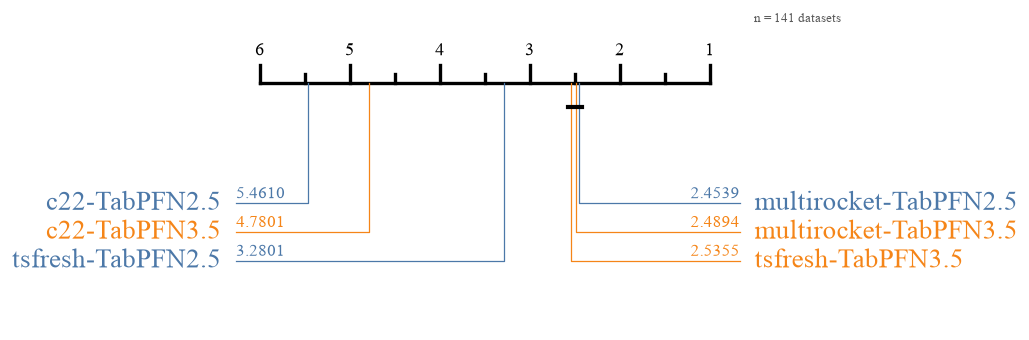

[redux] datasets used: 141 | baselines: 8 of 8 | TabPFN variants: ['multirocket-TabPFN2.5', 'multirocket-TabPFN3.5']


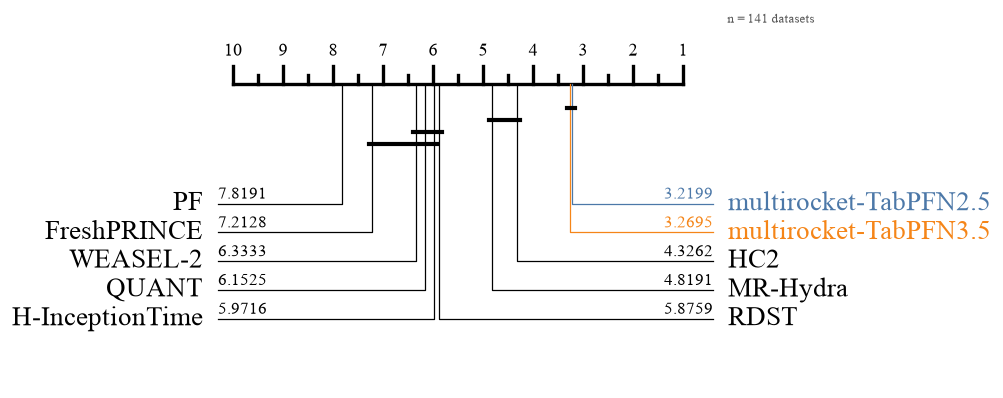

In [16]:
cd_tabpfn("redux")
cd_vs_baselines("redux")

                       datasets  median (MB)  mean (MB)  max (MB)
TabPFN2.5-c22               141        78.63      106.9     726.7
TabPFN2.5-tsfresh           141        408.5      537.9      3719
TabPFN2.5-multirocket       141        273.1      497.4      5221
TabPFN3.5-c22               141        923.5      948.7      1218
TabPFN3.5-tsfresh           141         2583       3086      6678
TabPFN3.5-multirocket       141         2782       3368      7207


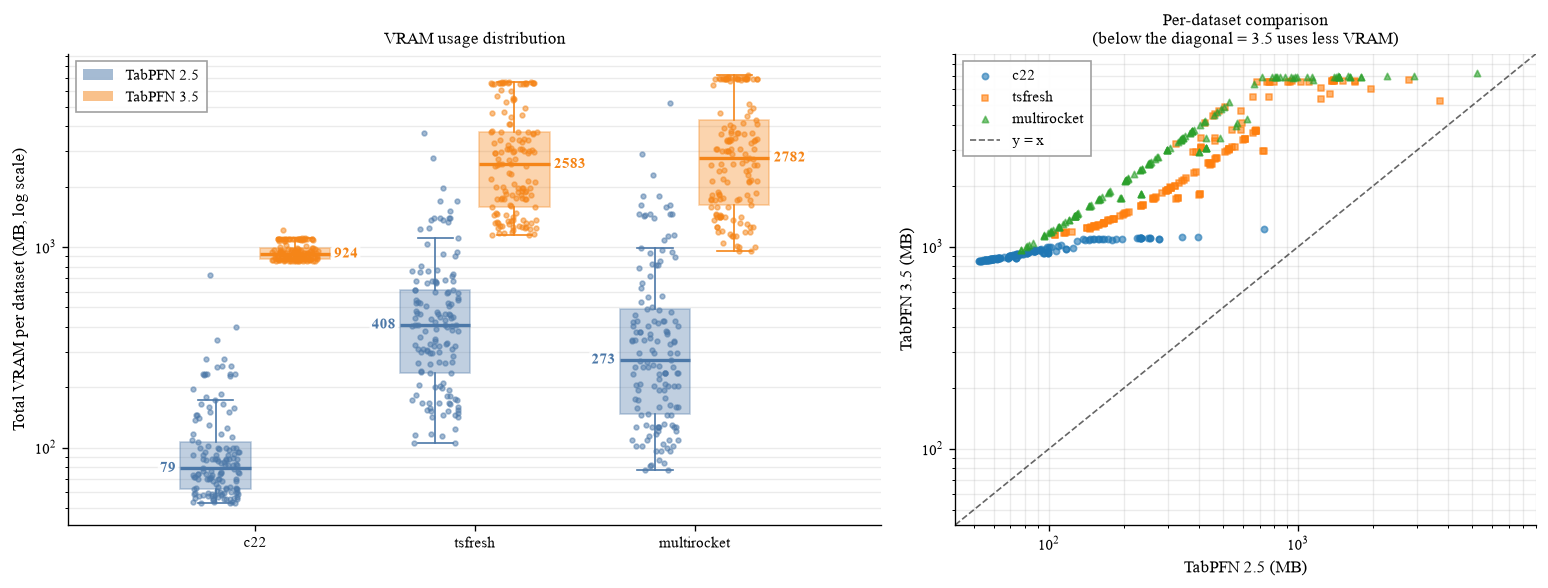

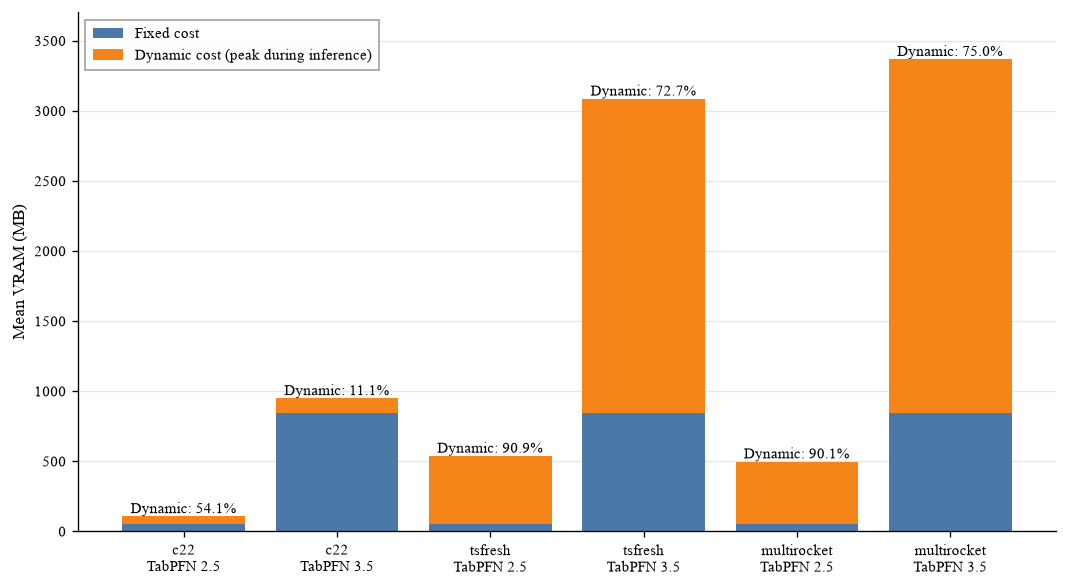

In [17]:
plot_cost_dist("redux", "vram_total_mb")
plot_vram_breakdown("redux")

                       datasets  median (s)  mean (s)  max (s)  total (s)
TabPFN2.5-c22               141      0.5198     2.056    25.22        290
TabPFN2.5-tsfresh           141       4.622     22.95    342.5       3236
TabPFN2.5-multirocket       141       28.36       122     1589  1.721e+04
TabPFN3.5-c22               141      0.7115     1.221    13.32      172.2
TabPFN3.5-tsfresh           141       3.716     8.107    81.12       1143
TabPFN3.5-multirocket       141       8.408     12.85    123.1       1811


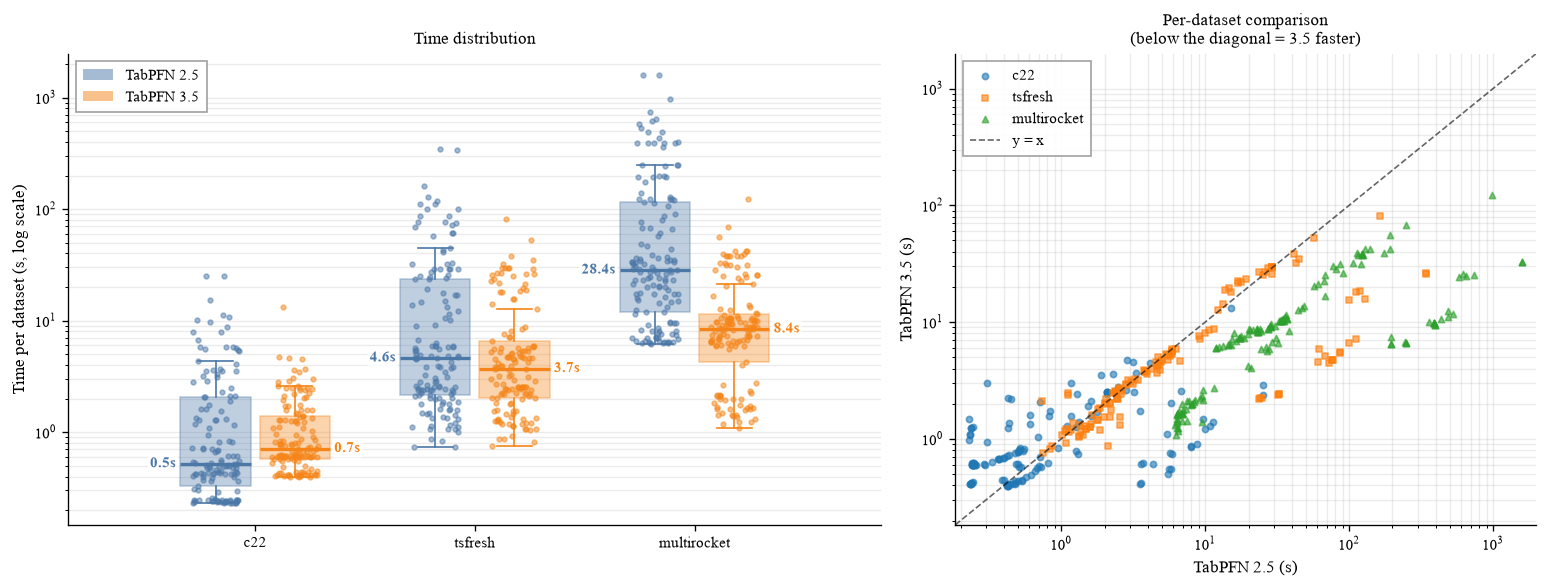

In [18]:
plot_cost_dist("redux", "inference_time")

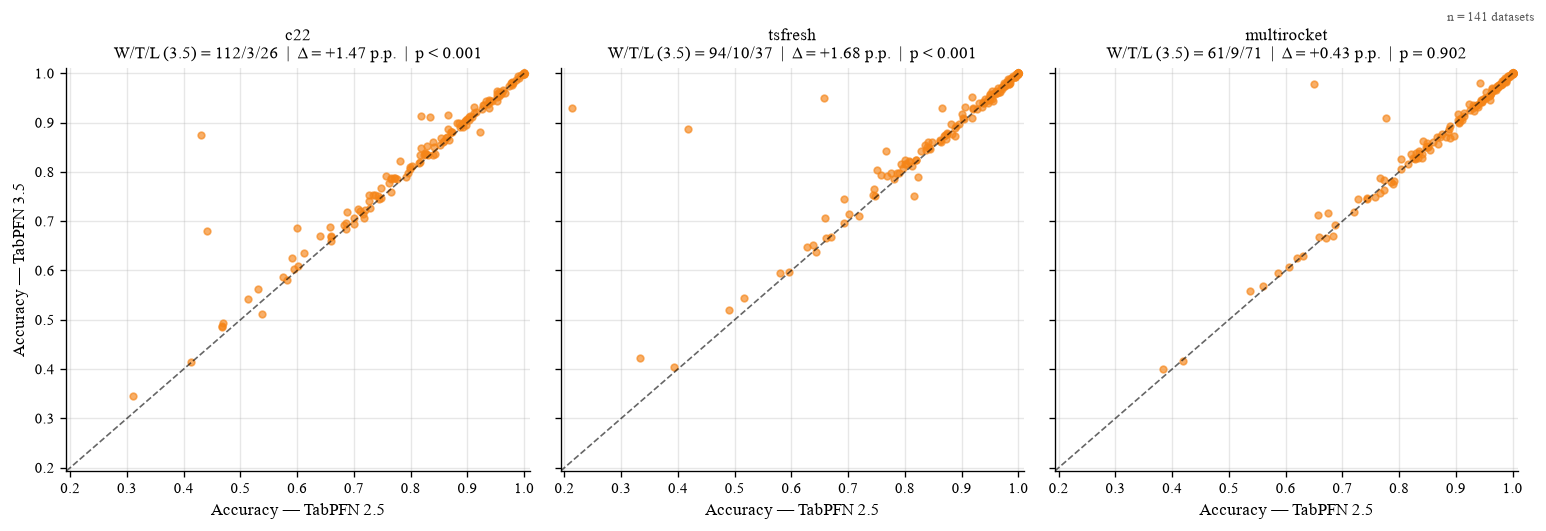

[redux] Spearman (inference_time × n_train): 2.5-c22=0.61, 2.5-tsfresh=0.68, 2.5-multirocket=0.69, 3.5-c22=0.44, 3.5-tsfresh=0.74, 3.5-multirocket=0.84
[redux] Spearman (vram_total_mb × n_train): 2.5-c22=0.73, 2.5-tsfresh=0.71, 2.5-multirocket=0.71, 3.5-c22=0.70, 3.5-tsfresh=0.70, 3.5-multirocket=0.70


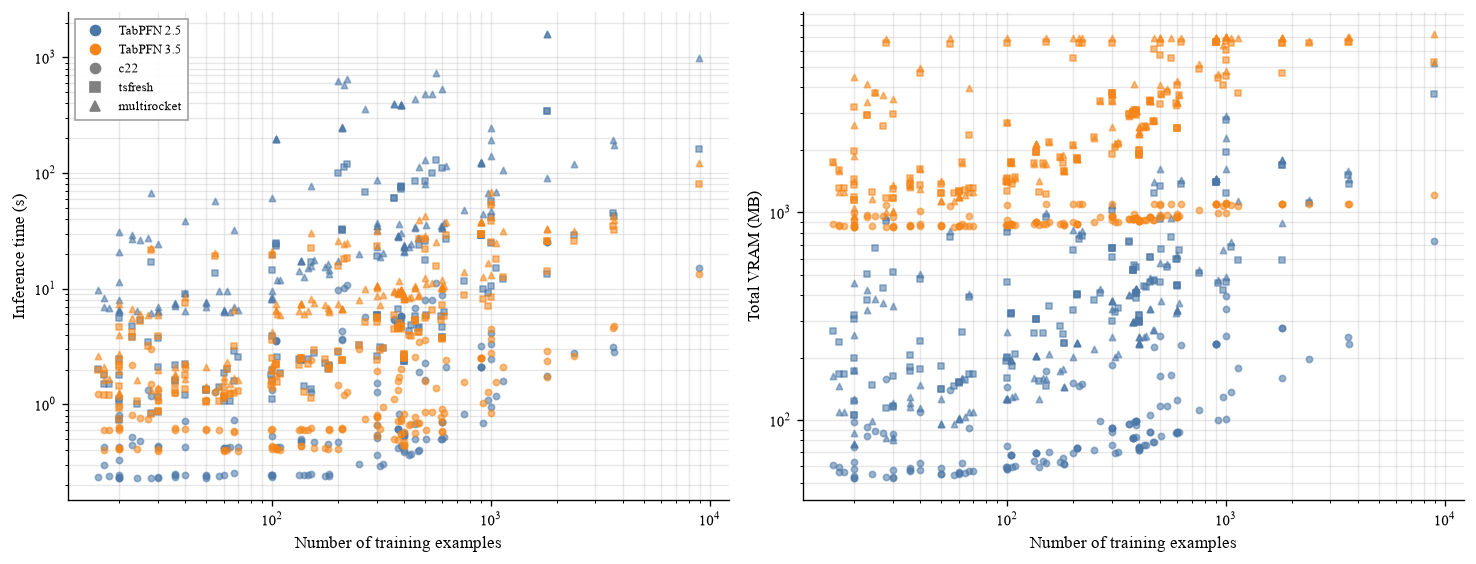

In [19]:
plot_acc_2v3("redux")
plot_scaling("redux")

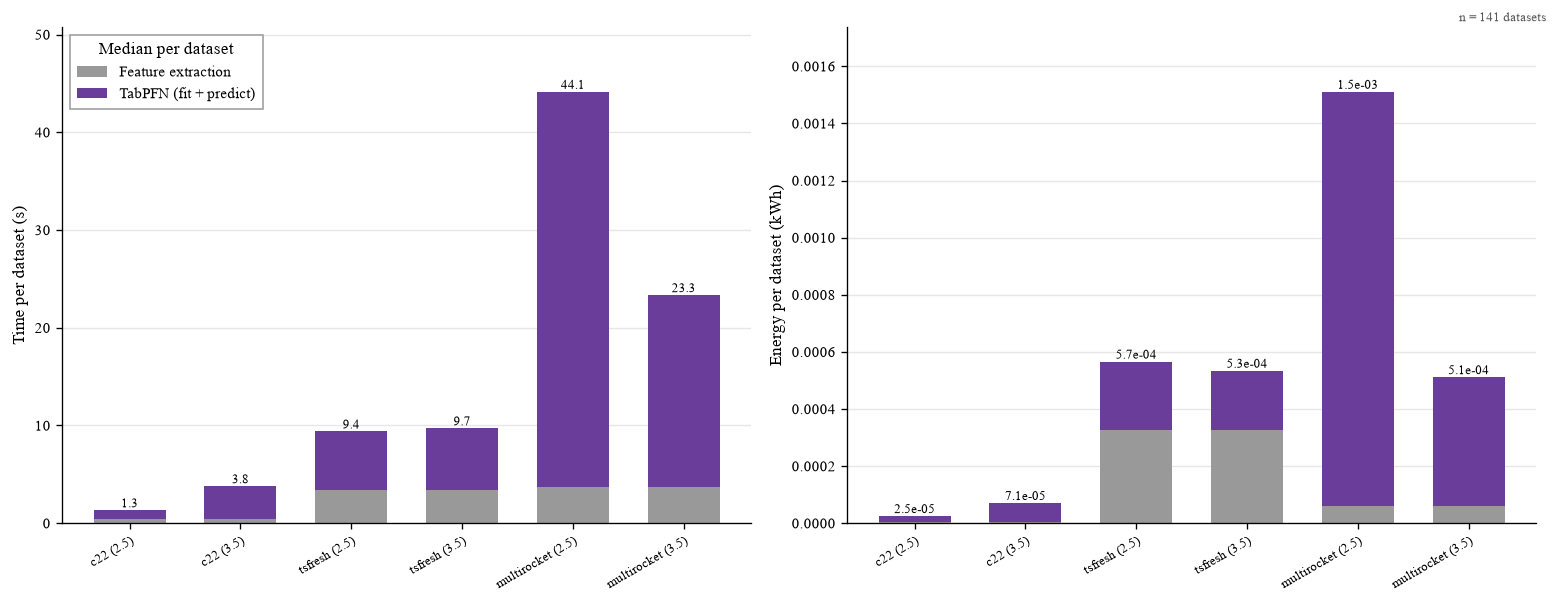

In [20]:
plot_pipeline_cost("redux")

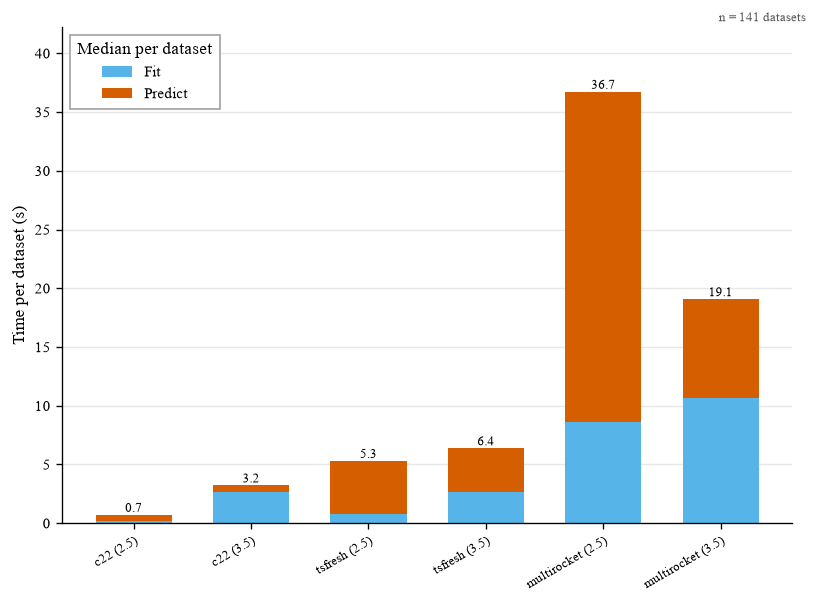

In [21]:
plot_fit_predict_time("redux")

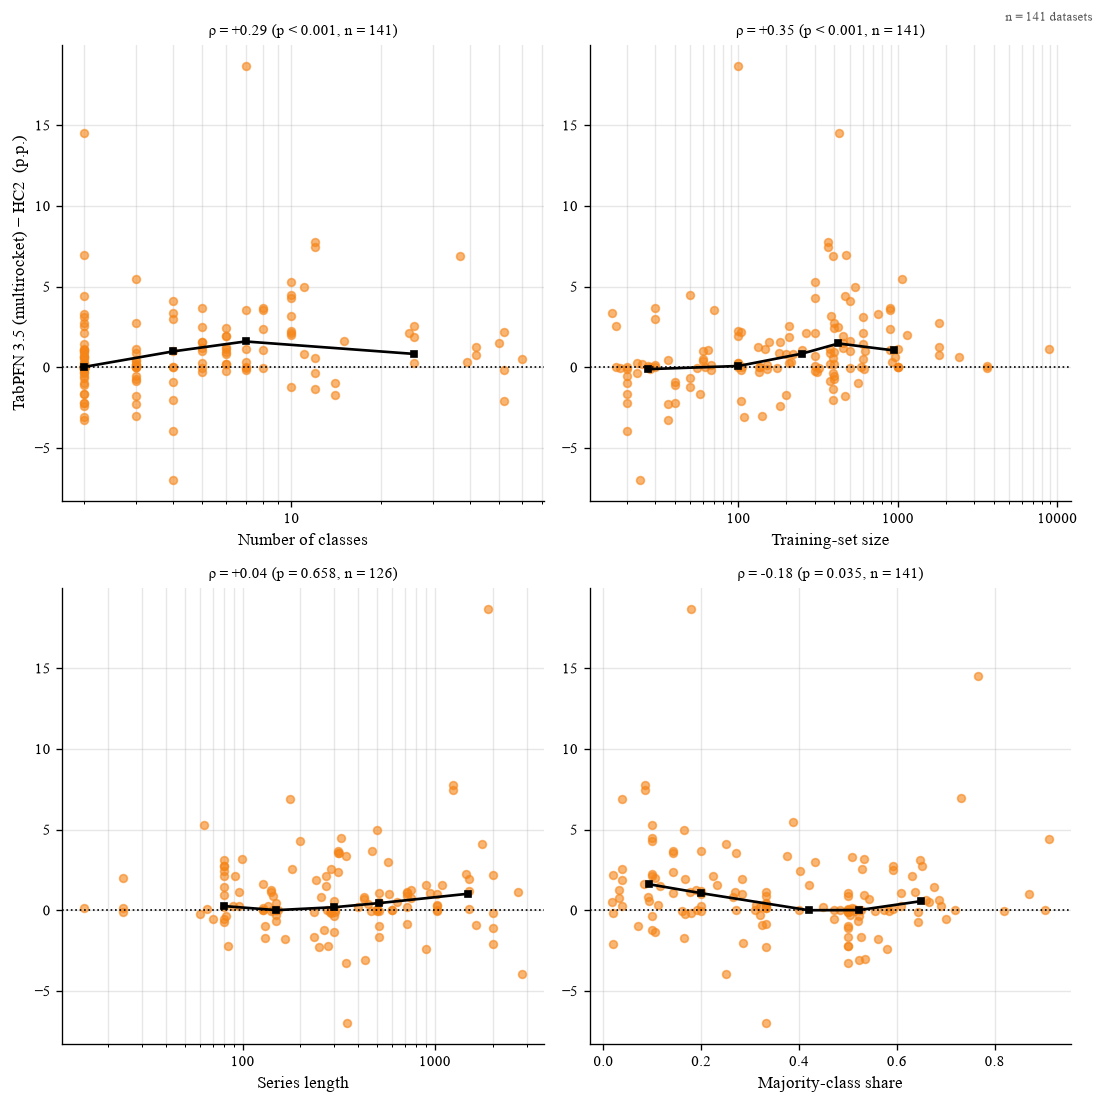

[redux] Spearman ρ of (TabPFN − HC2) with: Number of classes +0.29*, Training-set size +0.35*, Series length +0.04, Majority-class share -0.18*   (* p < 0.05)
[redux] TabPFN − HC2 (p.p.): largest advantages
                     delta  n_classes  n_train  length  channels
dataset                                                         
InlineSkate           18.7        7.0    100.0  1882.0       1.0
FloodModeling3_disc   14.5        2.0    429.0     NaN       1.0
EOGVerticalSignal      7.7       12.0    362.0  1250.0       1.0
EOGHorizontalSignal    7.5       12.0    362.0  1250.0       1.0
FloodModeling1_disc    7.0        2.0    471.0     NaN       1.0
[redux] largest disadvantages
                  delta  n_classes  n_train  length  channels
dataset                                                      
FaceFour           -7.0        4.0     24.0   350.0       1.0
Rock               -3.9        4.0     20.0  2844.0       1.0
ToeSegmentation2   -3.3        2.0     36.0   343.0       1.

In [22]:
plot_properties_full("redux")

## Multivariate (UEA - 30 runs)

[uea] datasets used: 20


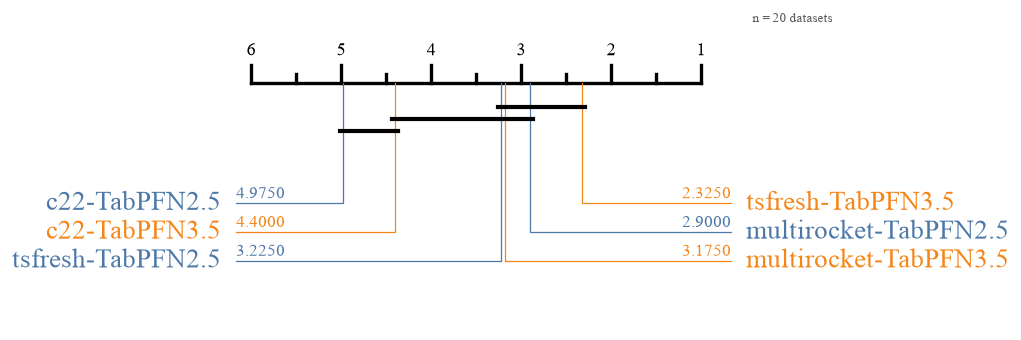

[uea] datasets used: 20 | baselines: 10 of 20 | TabPFN variants: ['tsfresh-TabPFN3.5', 'multirocket-TabPFN2.5']
  excluded for low dataset coverage: InceptionT (75%), MrSEQL (75%), MUSE (75%), TapNet (75%)


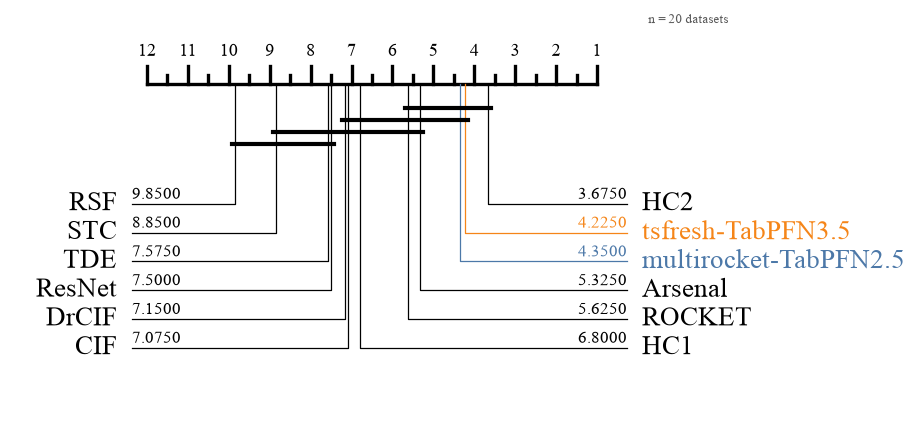

In [23]:
cd_tabpfn("uea")
cd_vs_baselines("uea")

                       datasets  median (MB)  mean (MB)  max (MB)
TabPFN2.5-c22                20        111.4      305.5      1861
TabPFN2.5-tsfresh            20        233.9      419.7      3126
TabPFN2.5-multirocket        20          179      434.8      2932
TabPFN3.5-c22                20         1026       1290      2871
TabPFN3.5-tsfresh            20         1626       2119      6925
TabPFN3.5-multirocket        20         1873       2366      6965

Datasets in the benchmark: 26


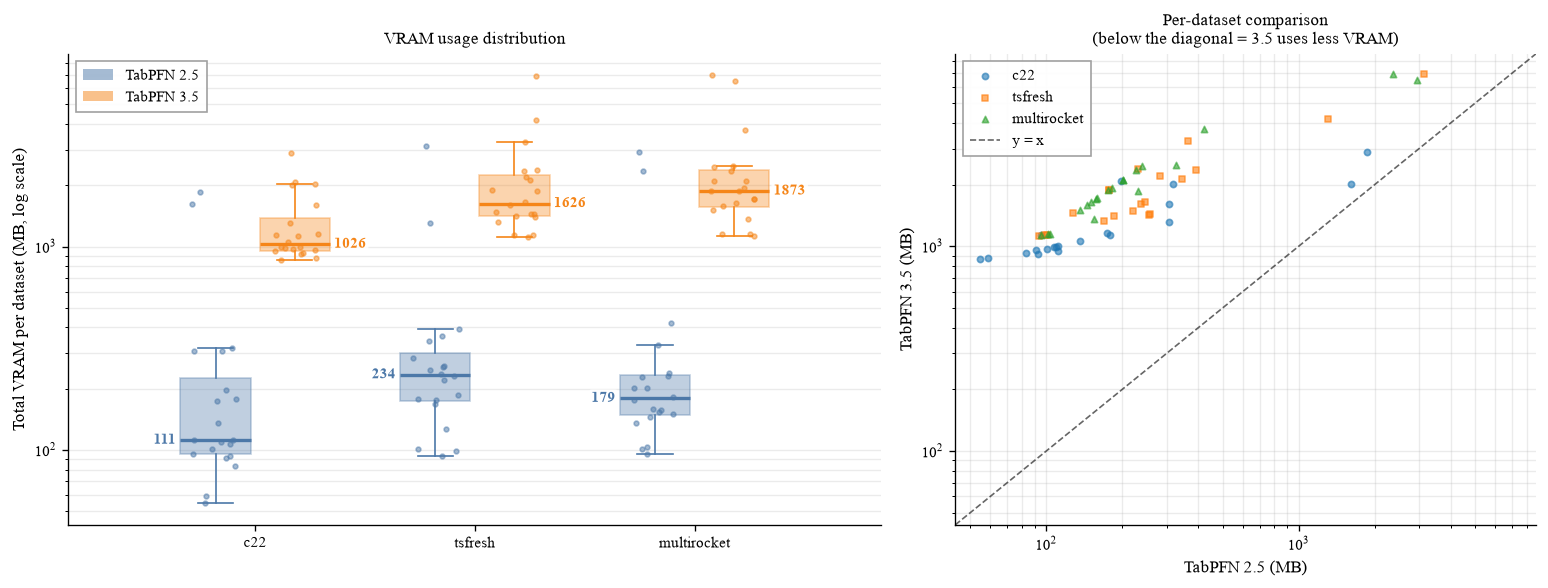

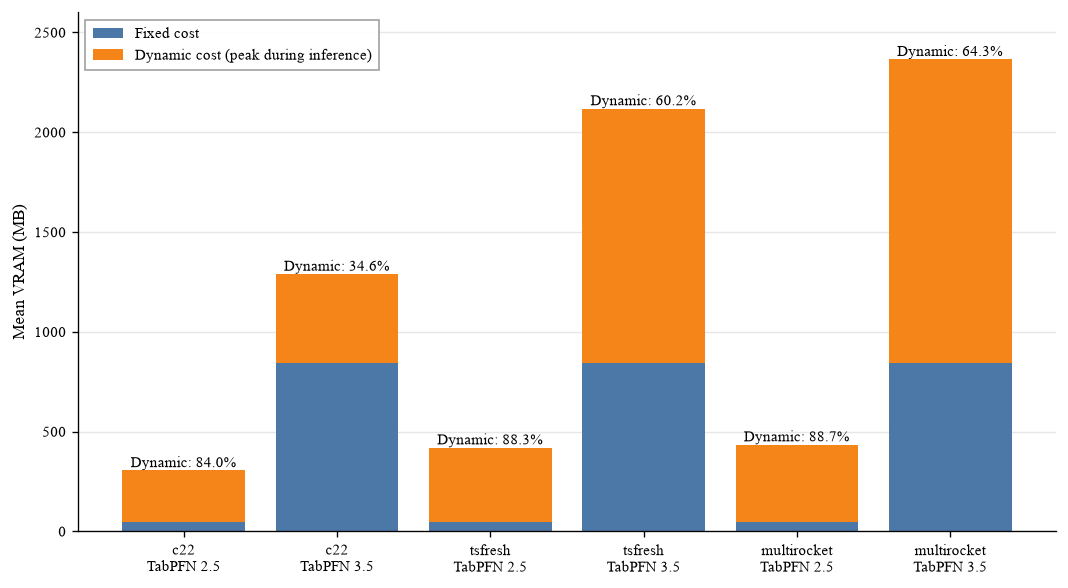

In [24]:
plot_cost_dist("uea", "vram_total_mb")
plot_vram_breakdown("uea")

                       datasets  median (s)  mean (s)  max (s)  total (s)
TabPFN2.5-c22                20      0.8401     9.849    124.6        197
TabPFN2.5-tsfresh            20       2.758     37.94      488      758.9
TabPFN2.5-multirocket        20       6.962     106.4    847.8       2129
TabPFN3.5-c22                20       0.529    0.9257    4.149      18.51
TabPFN3.5-tsfresh            20        1.36     3.918    36.74      78.35
TabPFN3.5-multirocket        20       3.915     4.713    16.73      94.26

Datasets in the benchmark: 26


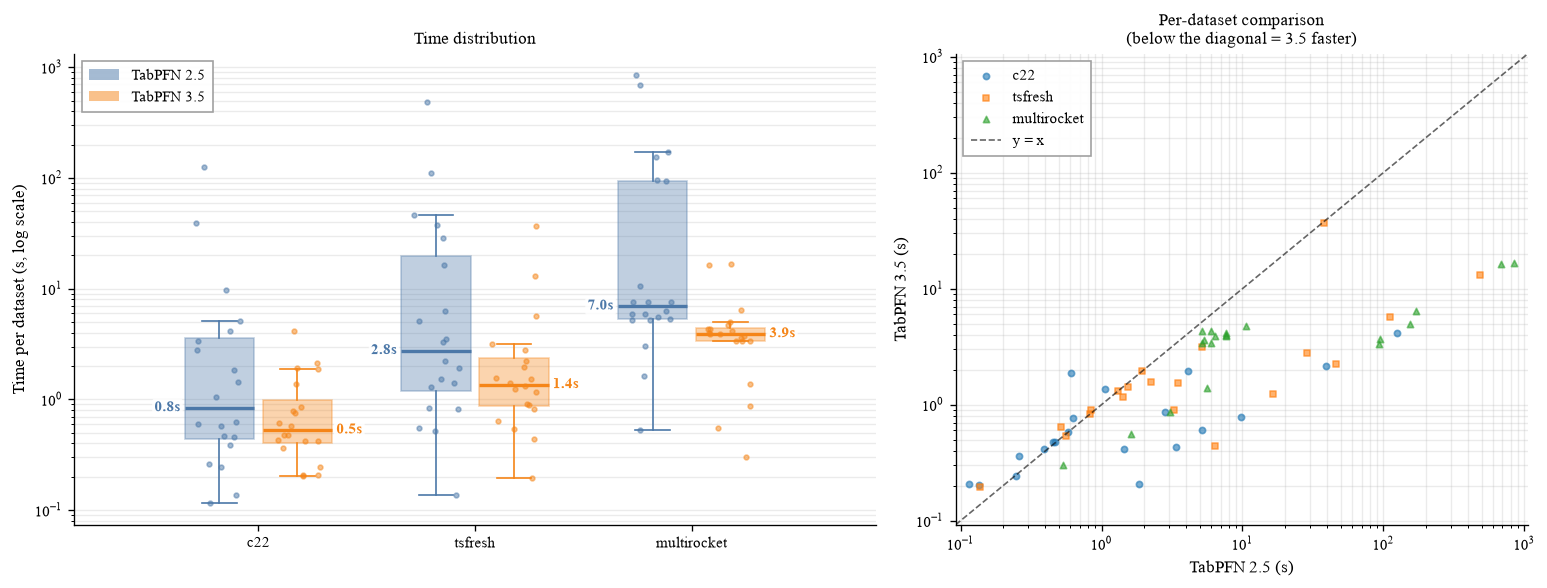

In [25]:
plot_cost_dist("uea", "inference_time")

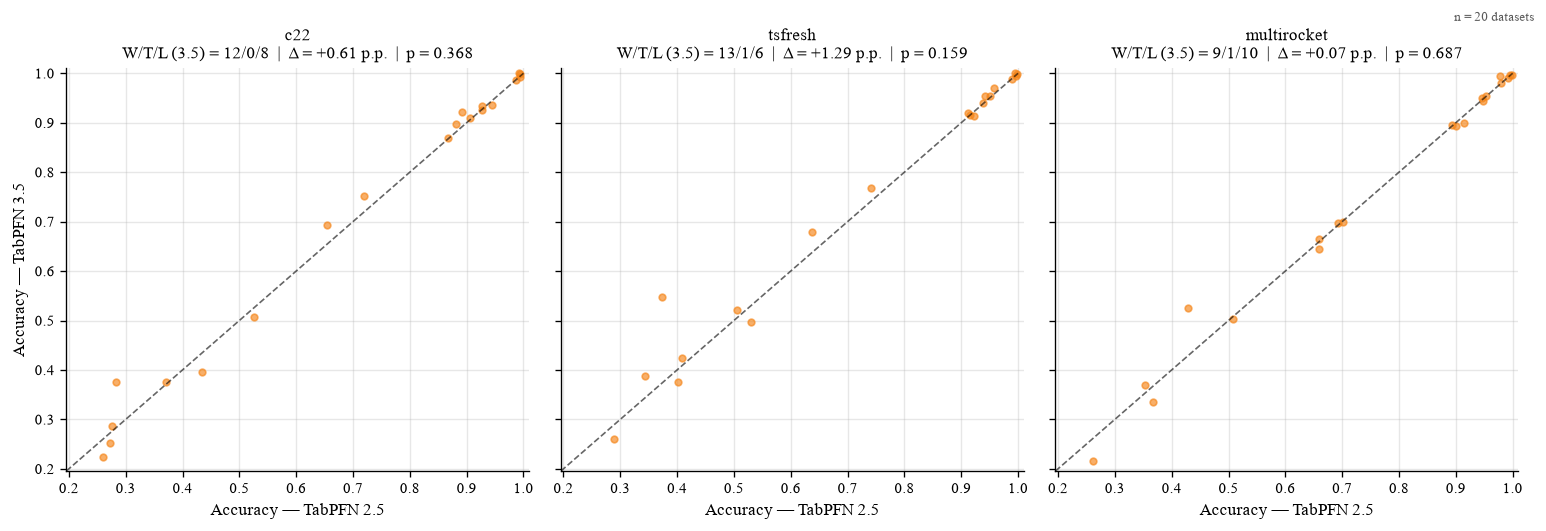

[uea] Spearman (inference_time × n_train): 2.5-c22=0.49, 2.5-tsfresh=0.69, 2.5-multirocket=0.55, 3.5-c22=0.48, 3.5-tsfresh=0.74, 3.5-multirocket=0.63
[uea] Spearman (vram_total_mb × n_train): 2.5-c22=0.85, 2.5-tsfresh=0.51, 2.5-multirocket=0.78, 3.5-c22=0.80, 3.5-tsfresh=0.76, 3.5-multirocket=0.81


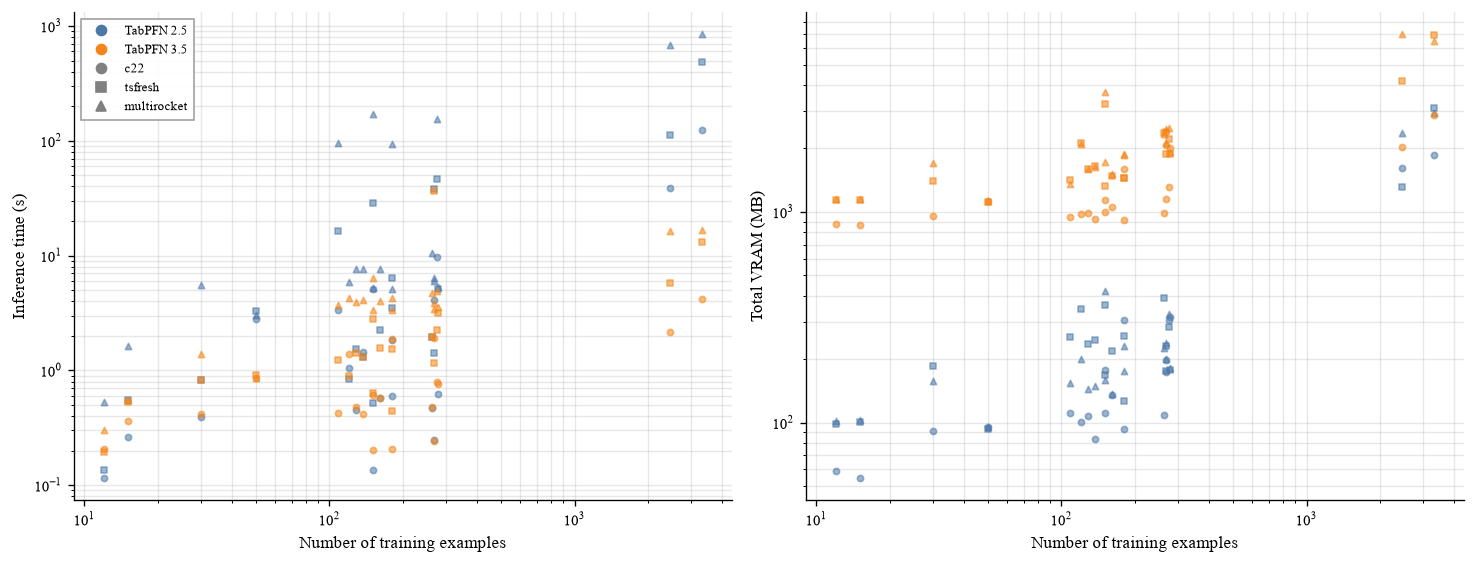

In [26]:
plot_acc_2v3("uea")
plot_scaling("uea")

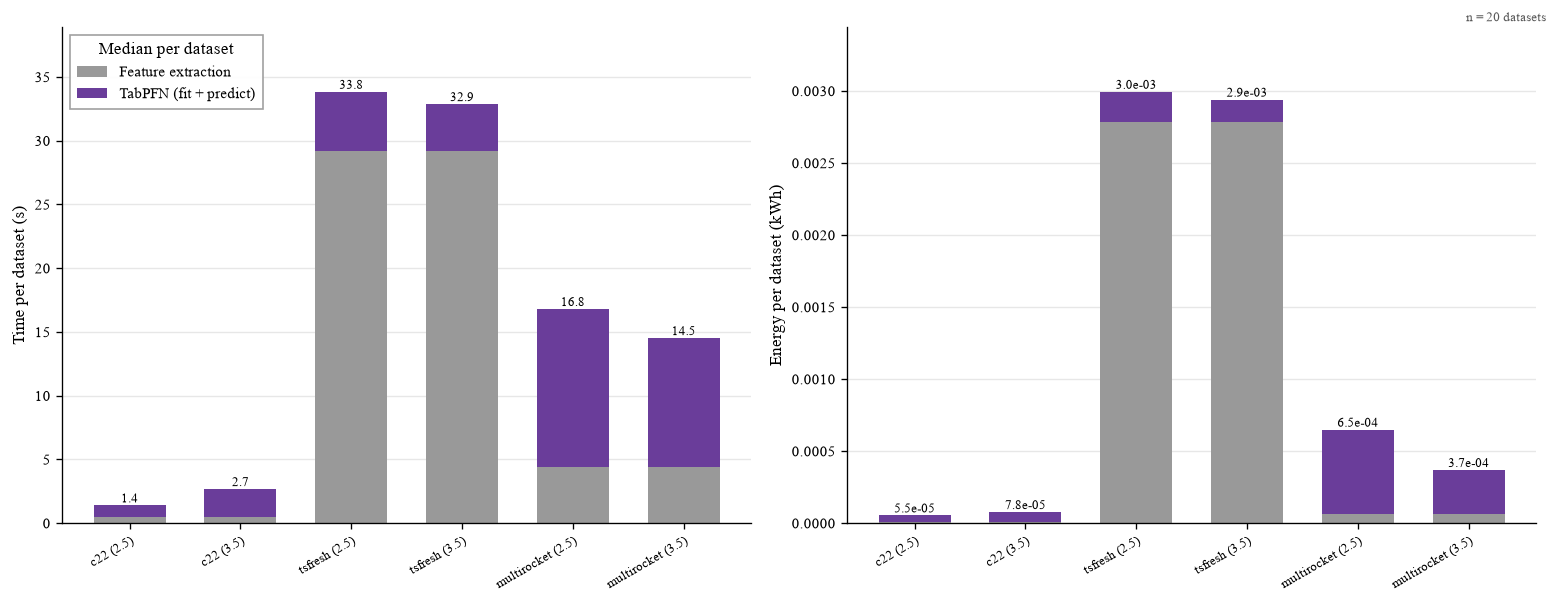

In [27]:
plot_pipeline_cost("uea")

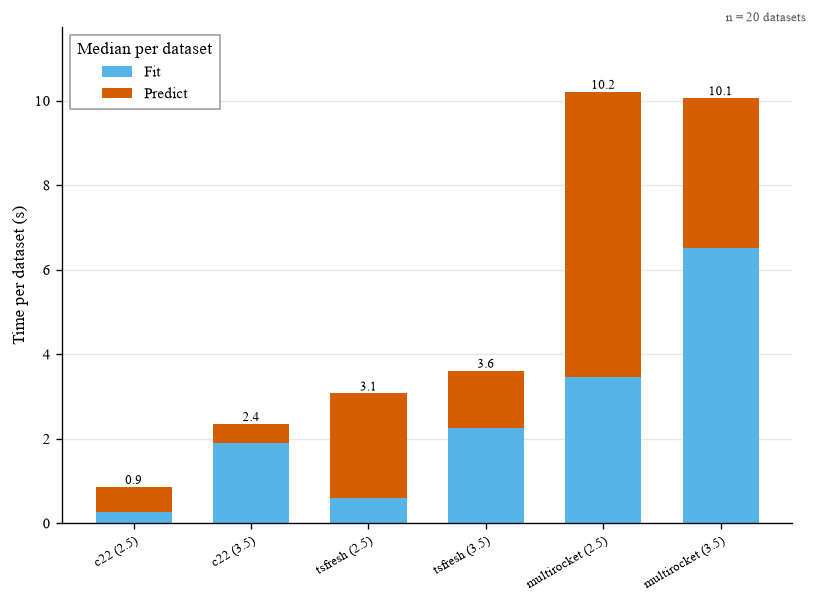

In [28]:
plot_fit_predict_time("uea")

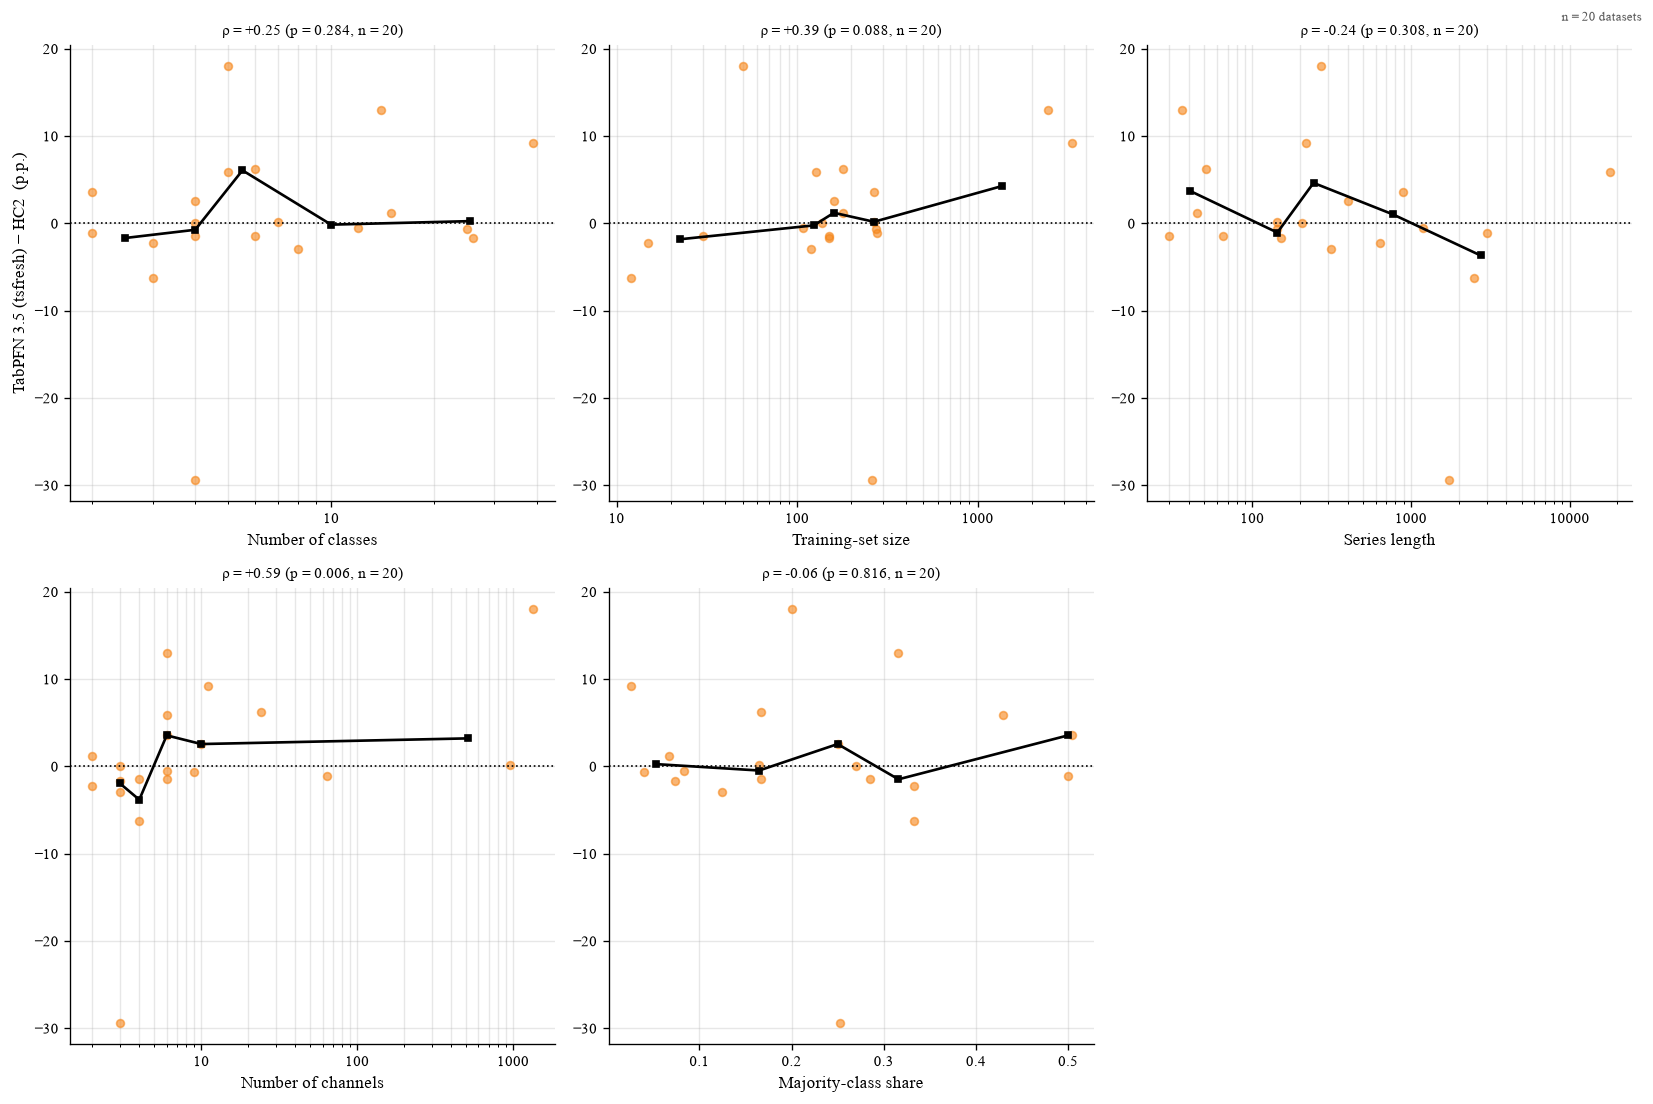

[uea] Spearman ρ of (TabPFN − HC2) with: Number of classes +0.25, Training-set size +0.39, Series length -0.24, Number of channels +0.59*, Majority-class share -0.06   (* p < 0.05)
[uea] TabPFN − HC2 (p.p.): largest advantages
                delta  n_classes  n_train   length  channels
dataset                                                     
DuckDuckGeese    18.1        5.0     50.0    270.0    1345.0
LSST             13.0       14.0   2459.0     36.0       6.0
PhonemeSpectra    9.3       39.0   3315.0    217.0      11.0
NATOPS            6.2        6.0    180.0     51.0      24.0
EigenWorms        5.9        5.0    128.0  17984.0       6.0
[uea] largest disadvantages
                      delta  n_classes  n_train  length  channels
dataset                                                          
EthanolConcentration  -29.4        4.0    261.0  1751.0       3.0
StandWalkJump          -6.2        3.0     12.0  2500.0       4.0
UWaveGestureLibrary    -3.0        8.0    120.0   315.

In [29]:
plot_properties_full("uea")

# Part II — Few-shot

PDFs go to `figs/few/`, with the benchmark in the file name.

## Univariate (Redux)

### Few-shot: TabPFN (selection methods, cost and comparison with full-shot)

In [30]:
print(summary_table("redux").round(3).to_string())

[redux] datasets in few-shot: 141 | valid in ALL methods/K: 107
  K=1: 141 valid datasets
  K=3: 132 valid datasets
  K=5: 126 valid datasets
  K=10: 107 valid datasets
                    n datasets                mean acc                      acc / full-shot                     
K                           1    3    5    10       1      3      5      10              1      3      5      10
method                                                                                                          
Random                     141  132  126  107    0.489  0.680  0.742  0.803           0.555  0.766  0.839  0.896
Stratified Random          141  132  126  107    0.548  0.702  0.739  0.798           0.616  0.789  0.834  0.889
KMedoids                   141  132  126  107    0.572  0.726  0.764  0.812           0.644  0.816  0.863  0.906
Stratified KMedoids        141  132  126  107    0.612  0.757  0.784  0.823           0.686  0.850  0.884  0.917


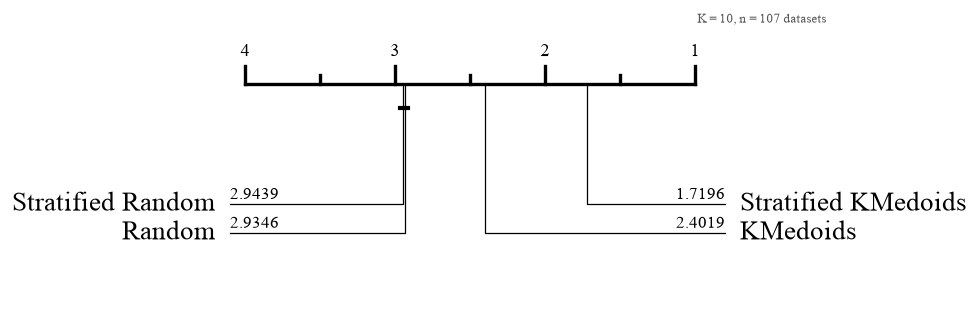

In [31]:
plot_cd_per_k("redux")

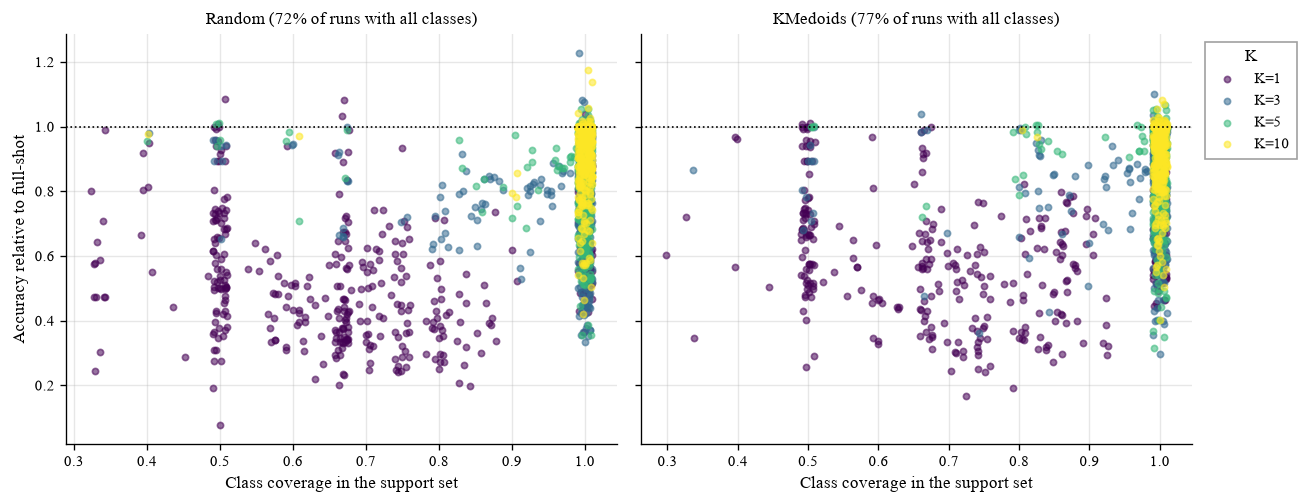

K                      1     3     5     10
method                                     
KMedoids             0.34  0.85  0.93  0.99
Random               0.21  0.83  0.91  0.99
Stratified KMedoids  1.00  1.00  1.00  1.00
Stratified Random    1.00  1.00  1.00  1.00


In [32]:
plot_coverage("redux")

Median of cost_few / cost_full per dataset (1.0 = same as full-shot):
K                                      1      3      5      10
metric         method                                         
inference_time KMedoids             0.377  0.447  0.454  0.490
               Random               0.385  0.450  0.455  0.488
               Stratified KMedoids  0.375  0.449  0.454  0.490
               Stratified Random    0.395  0.449  0.455  0.489
vram_data_mb   KMedoids             0.558  0.633  0.678  0.688
               Random               0.559  0.633  0.677  0.688
               Stratified KMedoids  0.559  0.633  0.678  0.688
               Stratified Random    0.558  0.633  0.677  0.688
vram_total_mb  KMedoids             0.804  0.822  0.830  0.844
               Random               0.803  0.818  0.830  0.841
               Stratified KMedoids  0.798  0.821  0.830  0.843
               Stratified Random    0.804  0.818  0.829  0.843


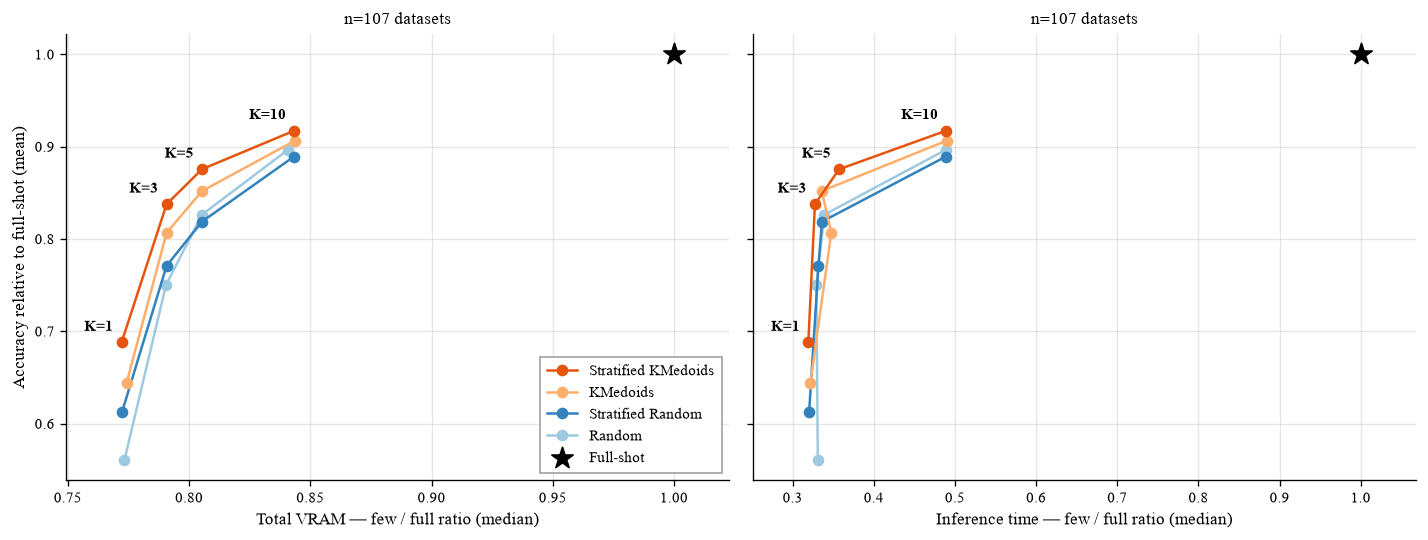

In [33]:
print("Median of cost_few / cost_full per dataset (1.0 = same as full-shot):")
print(cost_table("redux").round(3).to_string())
plot_tradeoff("redux")

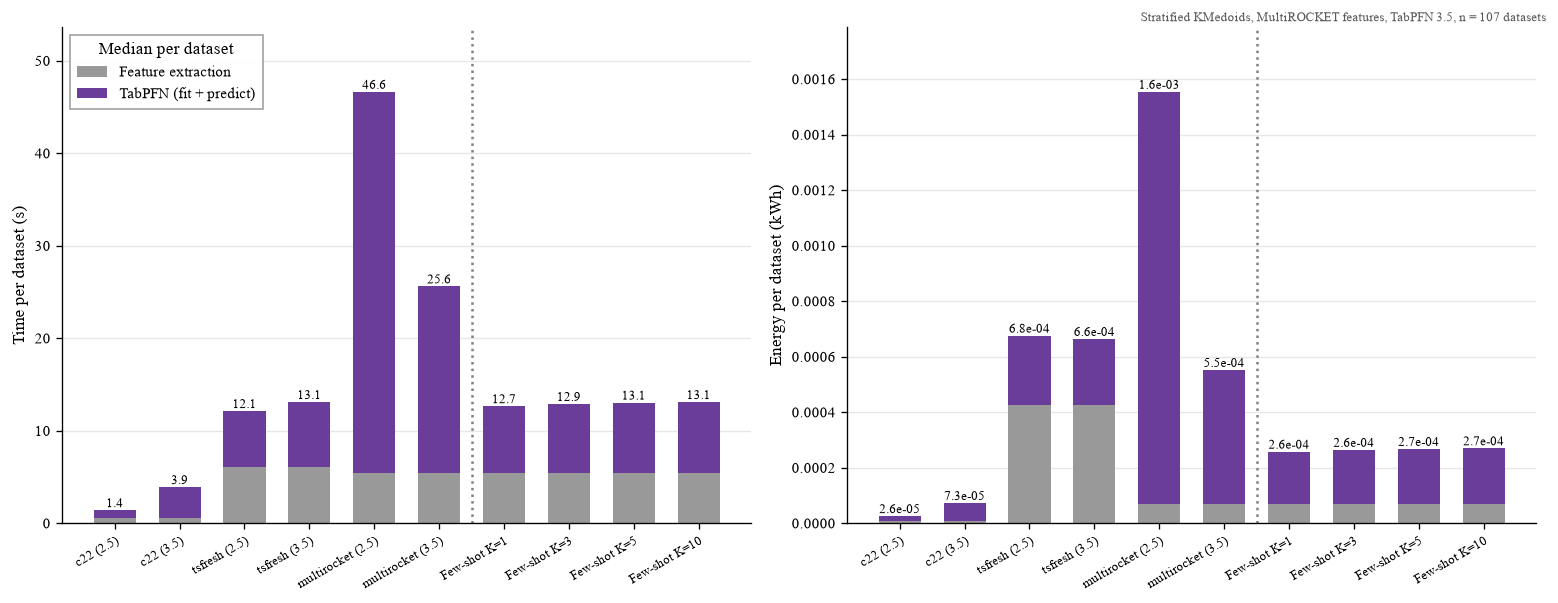

In [34]:
plot_pipeline_cost("redux", few=True)   # full-shot variants + few-shot (Stratified KMedoids) bars

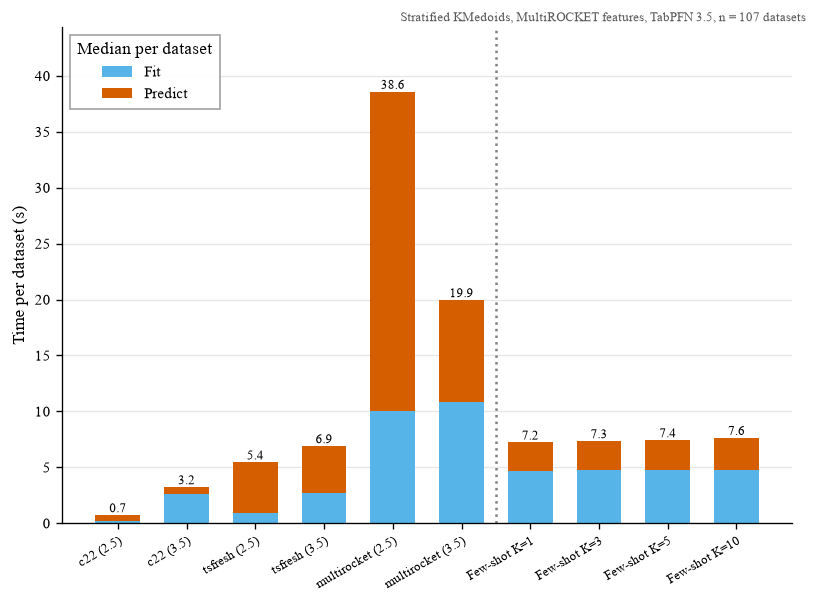

In [35]:
plot_fit_predict_time("redux", few=True)

[redux] state-of-the-art comparison: 107 datasets, 8 baselines (of 8)


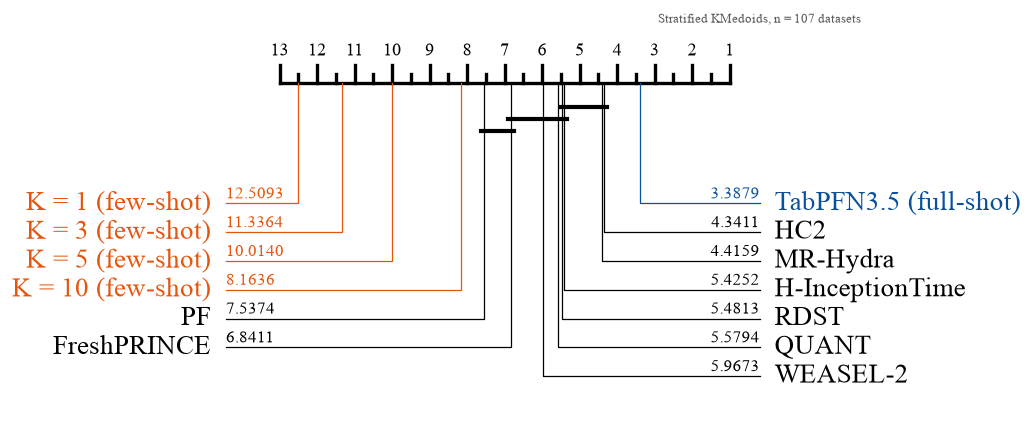

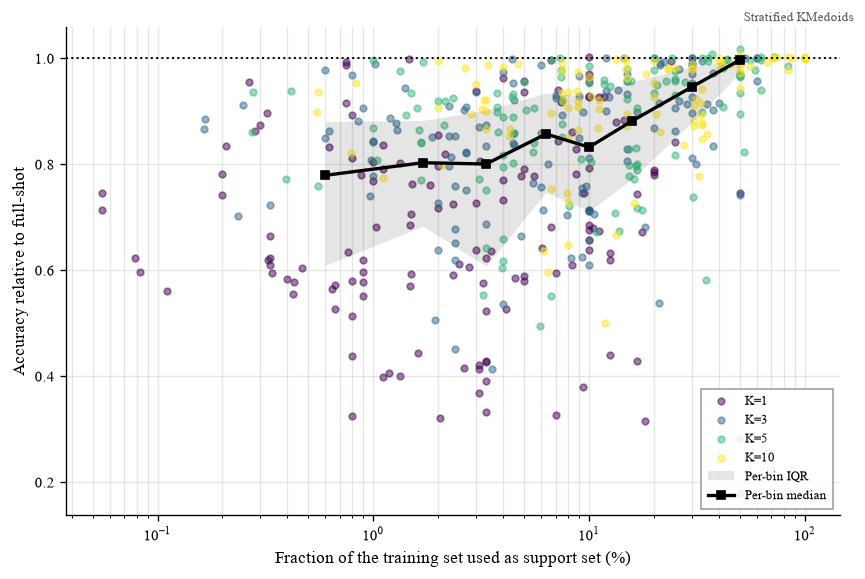

In [36]:
plot_vs_sota("redux")
plot_sample_efficiency("redux", "stratified_kmedoids")

[redux] K=1: ρ(retained accuracy, Number of classes) = -0.45* (n = 141)
[redux] K=3: ρ(retained accuracy, Number of classes) = -0.20* (n = 132)
[redux] K=5: ρ(retained accuracy, Number of classes) = -0.16 (n = 126)
[redux] K=10: ρ(retained accuracy, Number of classes) = -0.16 (n = 107)
[redux] K=1: ρ(retained accuracy, Training-set size) = -0.36* (n = 141)
[redux] K=3: ρ(retained accuracy, Training-set size) = -0.41* (n = 132)
[redux] K=5: ρ(retained accuracy, Training-set size) = -0.46* (n = 126)
[redux] K=10: ρ(retained accuracy, Training-set size) = -0.47* (n = 107)
[redux] K=1: ρ(retained accuracy, Series length) = -0.19* (n = 126)
[redux] K=3: ρ(retained accuracy, Series length) = -0.16 (n = 117)
[redux] K=5: ρ(retained accuracy, Series length) = -0.19* (n = 111)
[redux] K=10: ρ(retained accuracy, Series length) = -0.18 (n = 93)
[redux] K=1: ρ(retained accuracy, Majority-class share) = +0.37* (n = 141)
[redux] K=3: ρ(retained accuracy, Majority-class share) = +0.08 (n = 132)
[redu

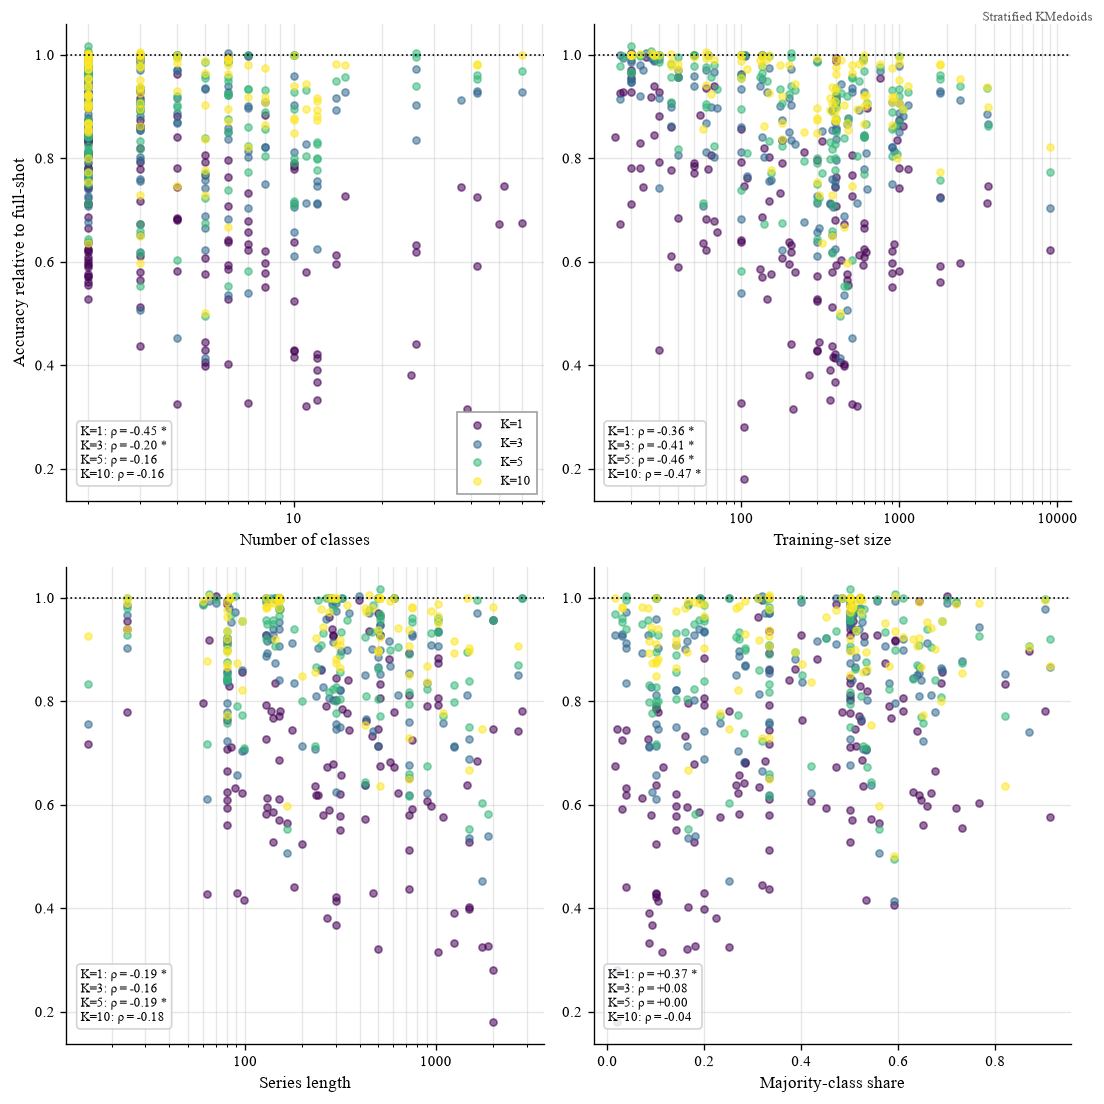

In [37]:
plot_properties_few("redux")

### Few-shot baselines: Ridge and 1NN (same support sets, same datasets)

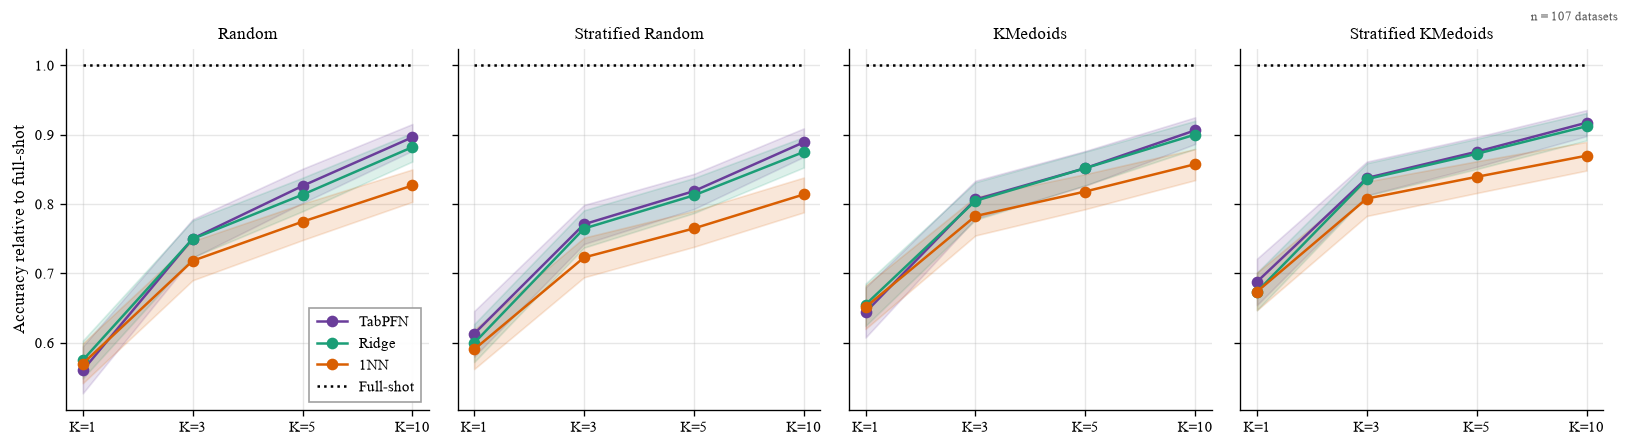

In [38]:
plot_models_vs_k("redux")

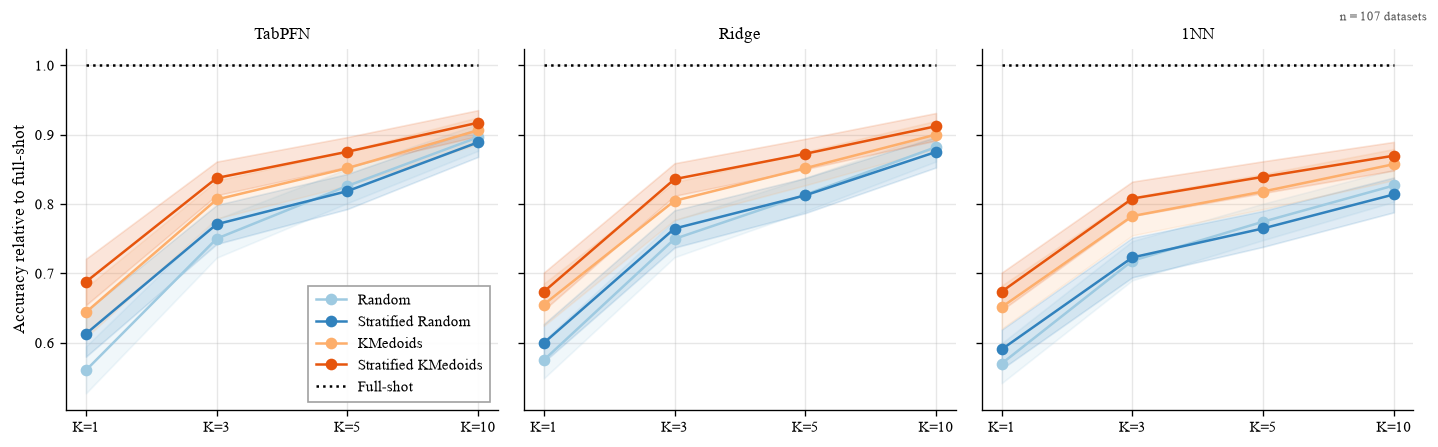

In [39]:
plot_selection_by_model("redux")

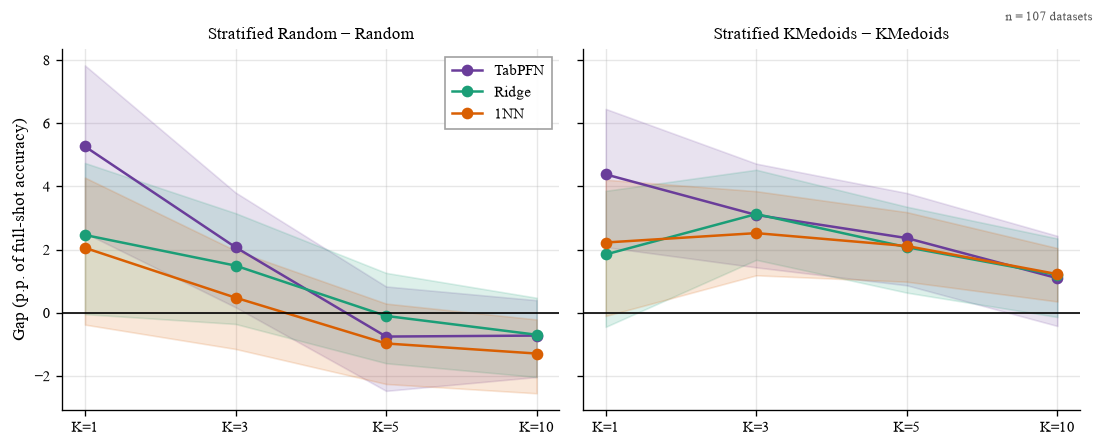

In [40]:
plot_oracle_gap("redux")

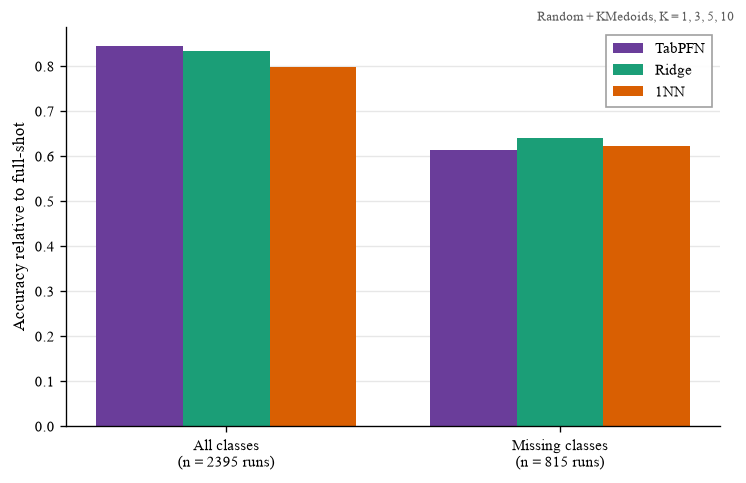

In [41]:
plot_coverage_models("redux")

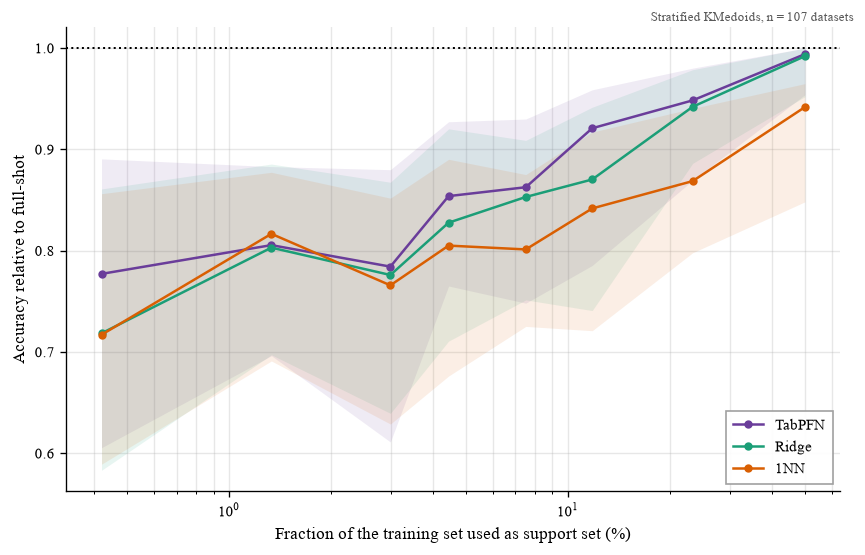

In [42]:
plot_sample_efficiency_models("redux")

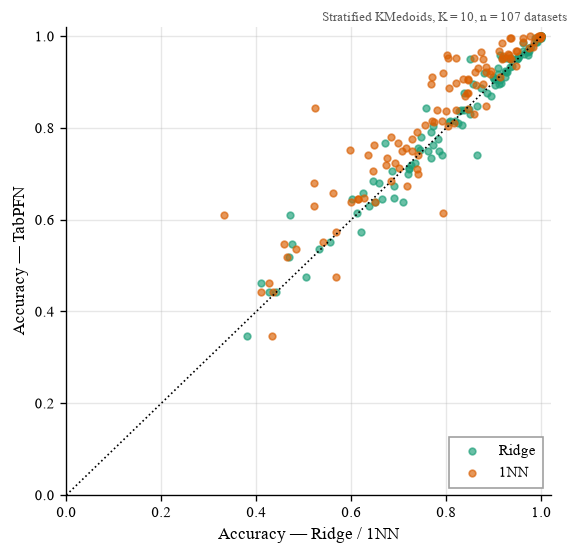

In [43]:
plot_scatter_baselines("redux", "stratified_kmedoids")

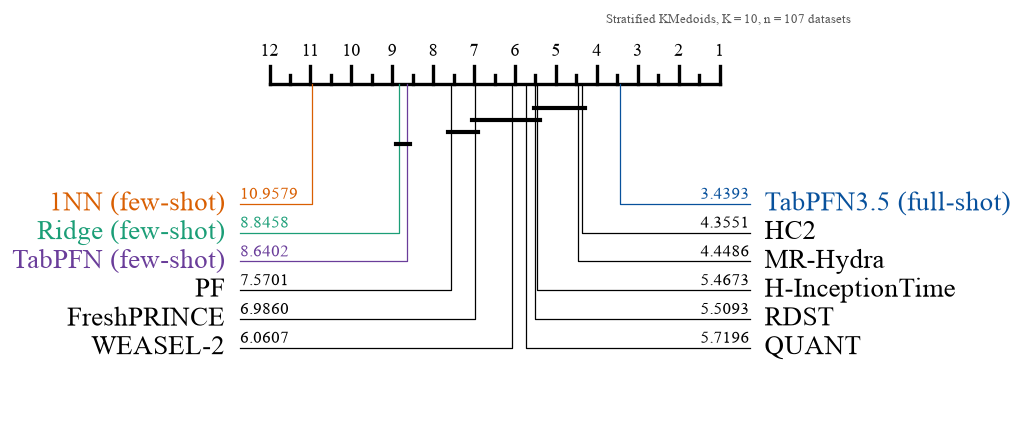

In [44]:
plot_cd_literature_models("redux", "stratified_kmedoids")

## Multivariate (UEA)

### Few-shot: TabPFN (selection methods, cost and comparison with full-shot)

In [45]:
print(summary_table("uea").round(3).to_string())

[uea] datasets in few-shot: 20 | valid in ALL methods/K: 14
  K=1: 20 valid datasets
  K=3: 19 valid datasets
  K=5: 18 valid datasets
  K=10: 14 valid datasets
                    n datasets             mean acc                      acc / full-shot                     
K                           1   3   5   10       1      3      5      10              1      3      5      10
method                                                                                                       
Random                      20  19  18  14    0.360  0.583  0.665  0.713           0.528  0.781  0.843  0.895
Stratified Random           20  19  18  14    0.442  0.599  0.655  0.720           0.600  0.797  0.827  0.894
KMedoids                    20  19  18  14    0.385  0.574  0.647  0.709           0.547  0.750  0.817  0.885
Stratified KMedoids         20  19  18  14    0.468  0.613  0.669  0.715           0.644  0.792  0.845  0.883


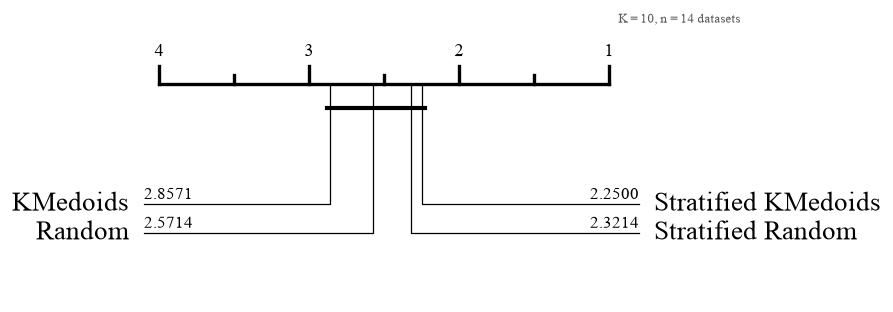

In [46]:
plot_cd_per_k("uea")

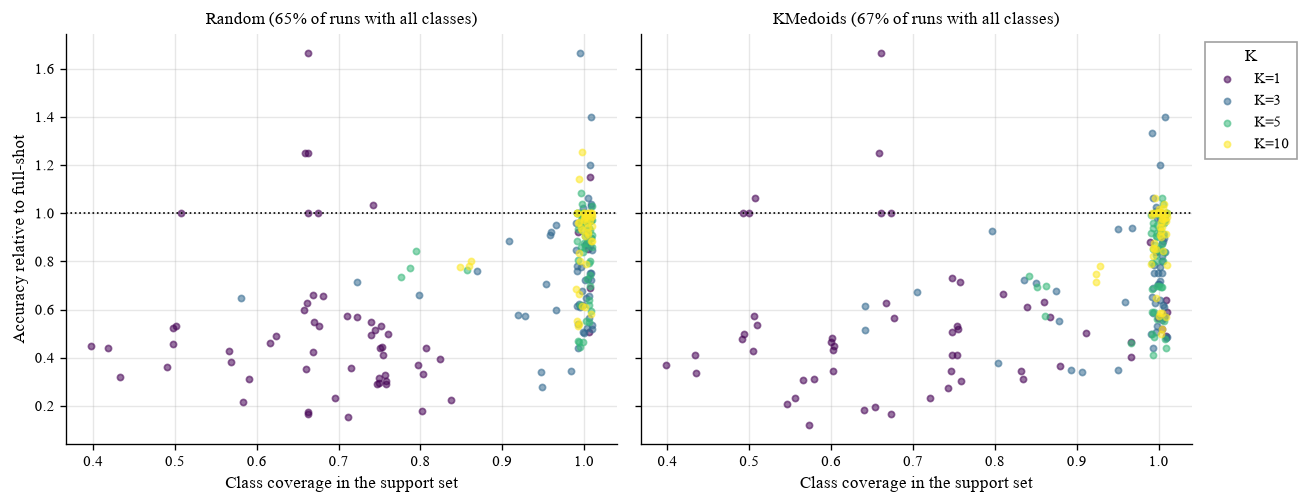

K                      1     3     5     10
method                                     
KMedoids             0.15  0.75  0.91  0.93
Random               0.08  0.75  0.93  0.93
Stratified KMedoids  1.00  1.00  1.00  1.00
Stratified Random    1.00  1.00  1.00  1.00


In [47]:
plot_coverage("uea")

Median of cost_few / cost_full per dataset (1.0 = same as full-shot):
K                                      1      3      5      10
metric         method                                         
inference_time KMedoids             0.333  0.336  0.356  0.325
               Random               0.380  0.308  0.353  0.326
               Stratified KMedoids  0.339  0.296  0.346  0.328
               Stratified Random    0.341  0.305  0.338  0.330
vram_data_mb   KMedoids             0.573  0.638  0.689  0.680
               Random               0.574  0.637  0.685  0.680
               Stratified KMedoids  0.573  0.638  0.689  0.680
               Stratified Random    0.573  0.636  0.685  0.679
vram_total_mb  KMedoids             0.828  0.847  0.851  0.867
               Random               0.828  0.846  0.850  0.868
               Stratified KMedoids  0.827  0.847  0.851  0.868
               Stratified Random    0.828  0.845  0.850  0.868


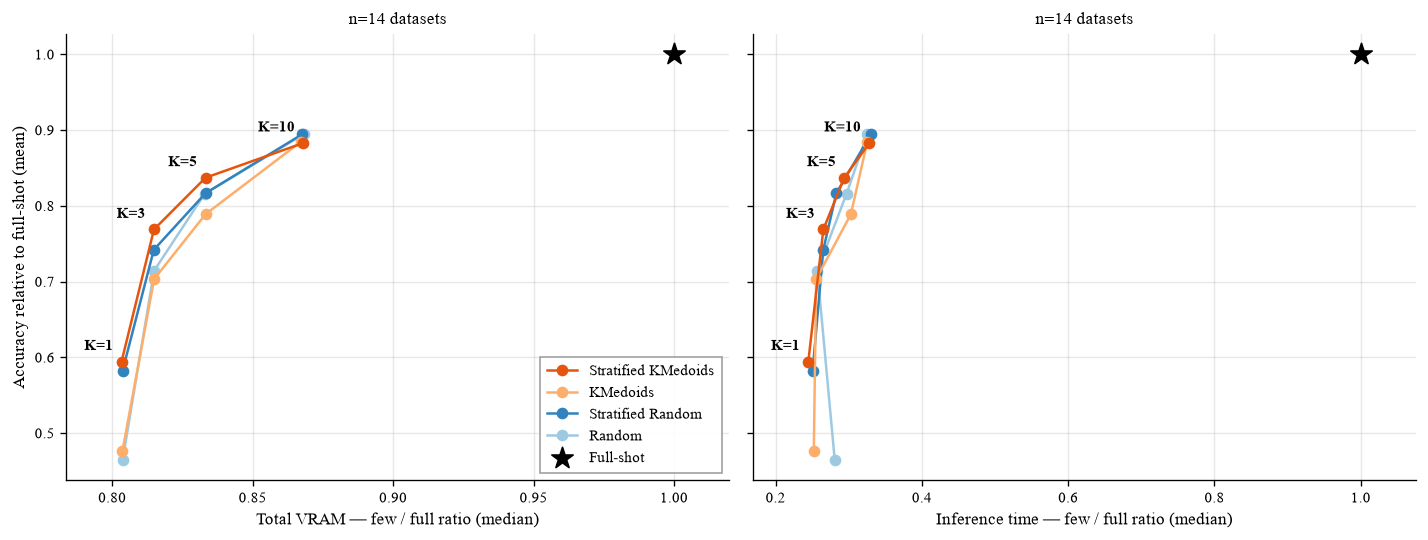

In [48]:
print("Median of cost_few / cost_full per dataset (1.0 = same as full-shot):")
print(cost_table("uea").round(3).to_string())
plot_tradeoff("uea")

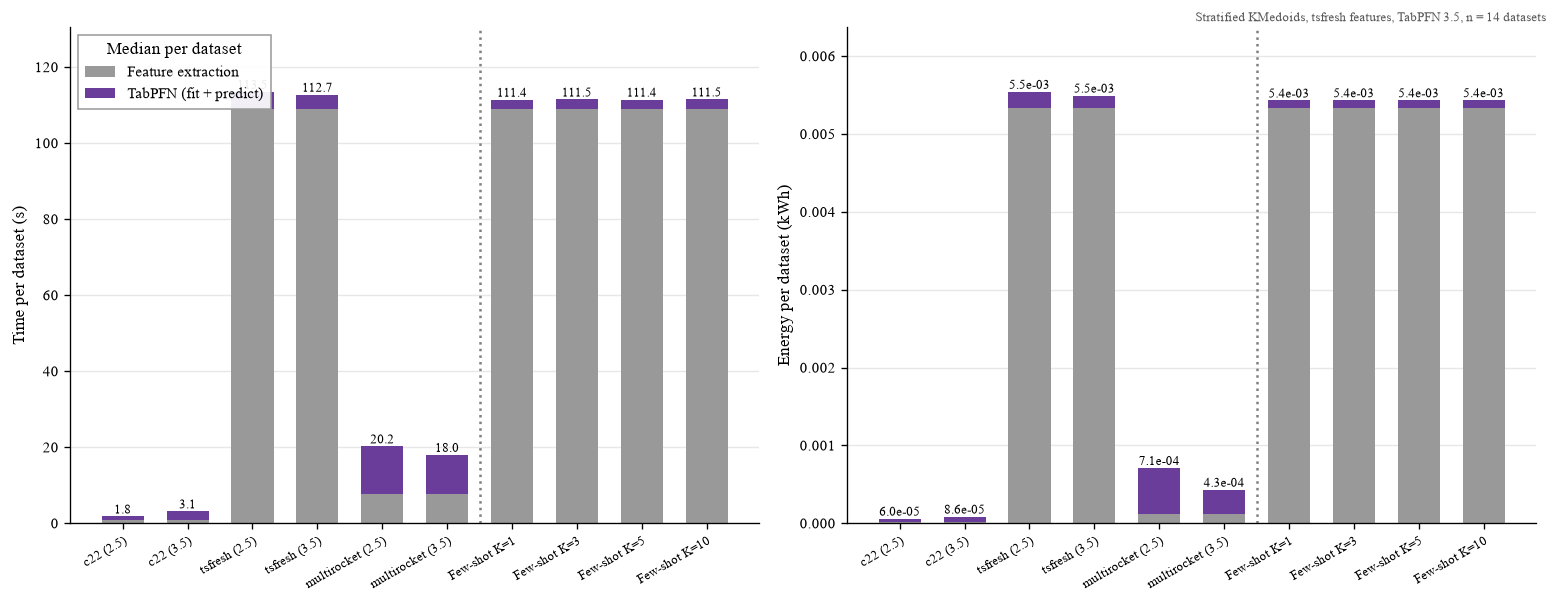

In [49]:
plot_pipeline_cost("uea", few=True)   # full-shot variants + few-shot (Stratified KMedoids) bars

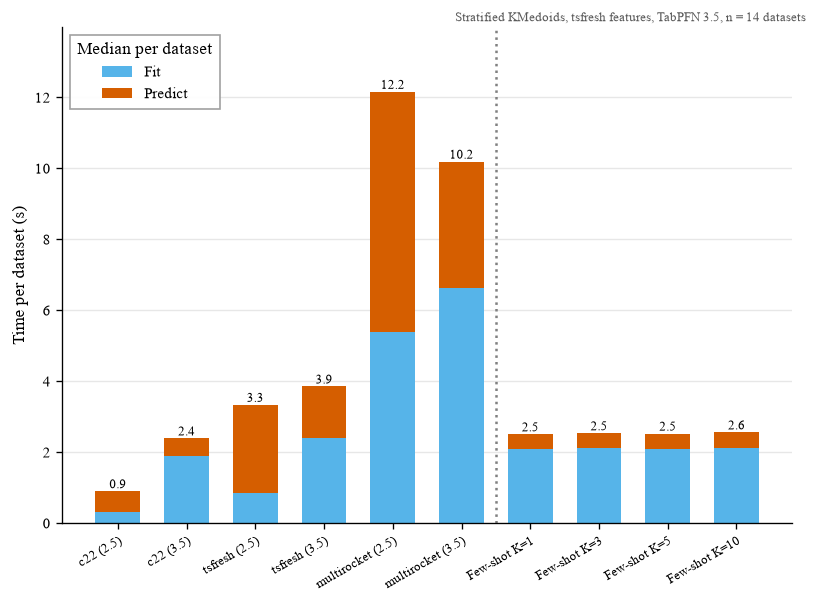

In [50]:
plot_fit_predict_time("uea", few=True)

[uea] state-of-the-art comparison: 14 datasets, 10 baselines (of 16)


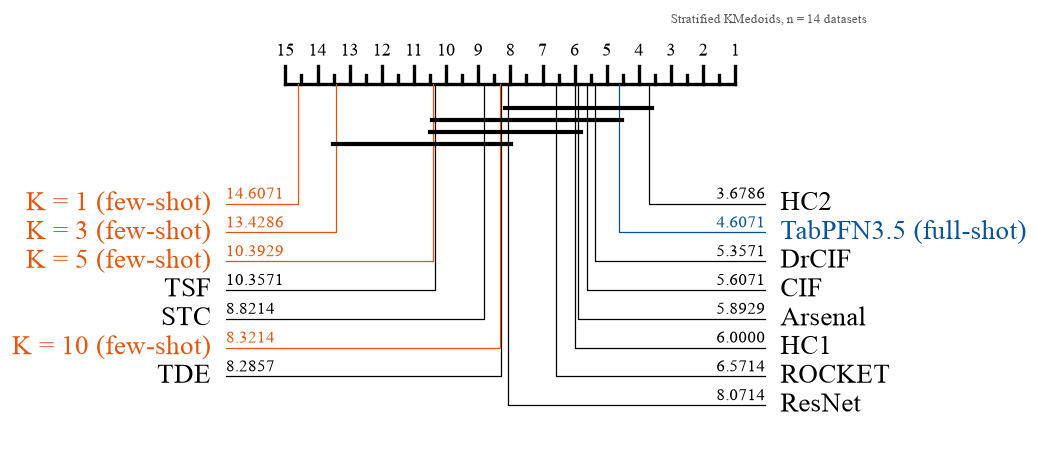

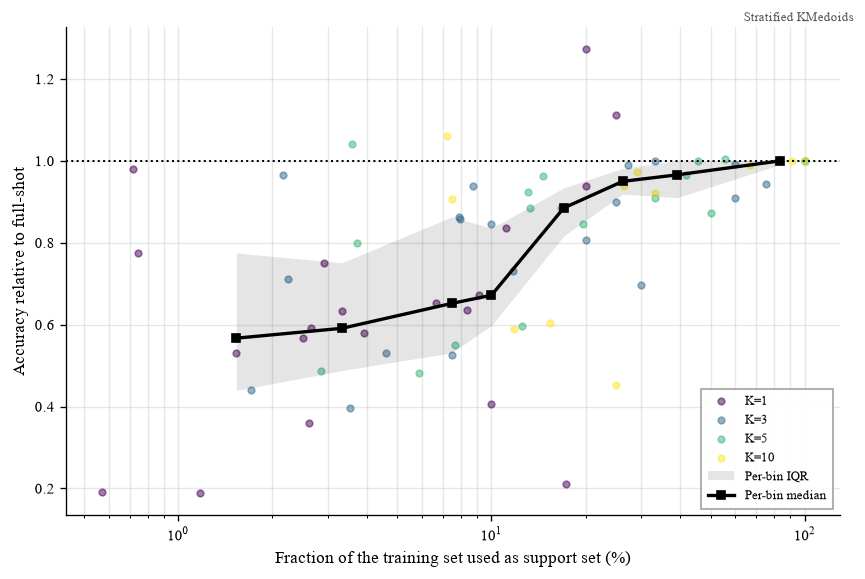

In [51]:
plot_vs_sota("uea")
plot_sample_efficiency("uea", "stratified_kmedoids")

[uea] K=1: ρ(retained accuracy, Number of classes) = -0.55* (n = 20)
[uea] K=3: ρ(retained accuracy, Number of classes) = -0.07 (n = 19)
[uea] K=5: ρ(retained accuracy, Number of classes) = -0.05 (n = 18)
[uea] K=10: ρ(retained accuracy, Number of classes) = +0.13 (n = 14)
[uea] K=1: ρ(retained accuracy, Training-set size) = -0.47* (n = 20)
[uea] K=3: ρ(retained accuracy, Training-set size) = -0.39 (n = 19)
[uea] K=5: ρ(retained accuracy, Training-set size) = -0.36 (n = 18)
[uea] K=10: ρ(retained accuracy, Training-set size) = -0.16 (n = 14)
[uea] K=1: ρ(retained accuracy, Series length) = +0.35 (n = 20)
[uea] K=3: ρ(retained accuracy, Series length) = +0.05 (n = 19)
[uea] K=5: ρ(retained accuracy, Series length) = +0.04 (n = 18)
[uea] K=10: ρ(retained accuracy, Series length) = -0.10 (n = 14)
[uea] K=1: ρ(retained accuracy, Number of channels) = -0.32 (n = 20)
[uea] K=3: ρ(retained accuracy, Number of channels) = -0.21 (n = 19)
[uea] K=5: ρ(retained accuracy, Number of channels) = -0.

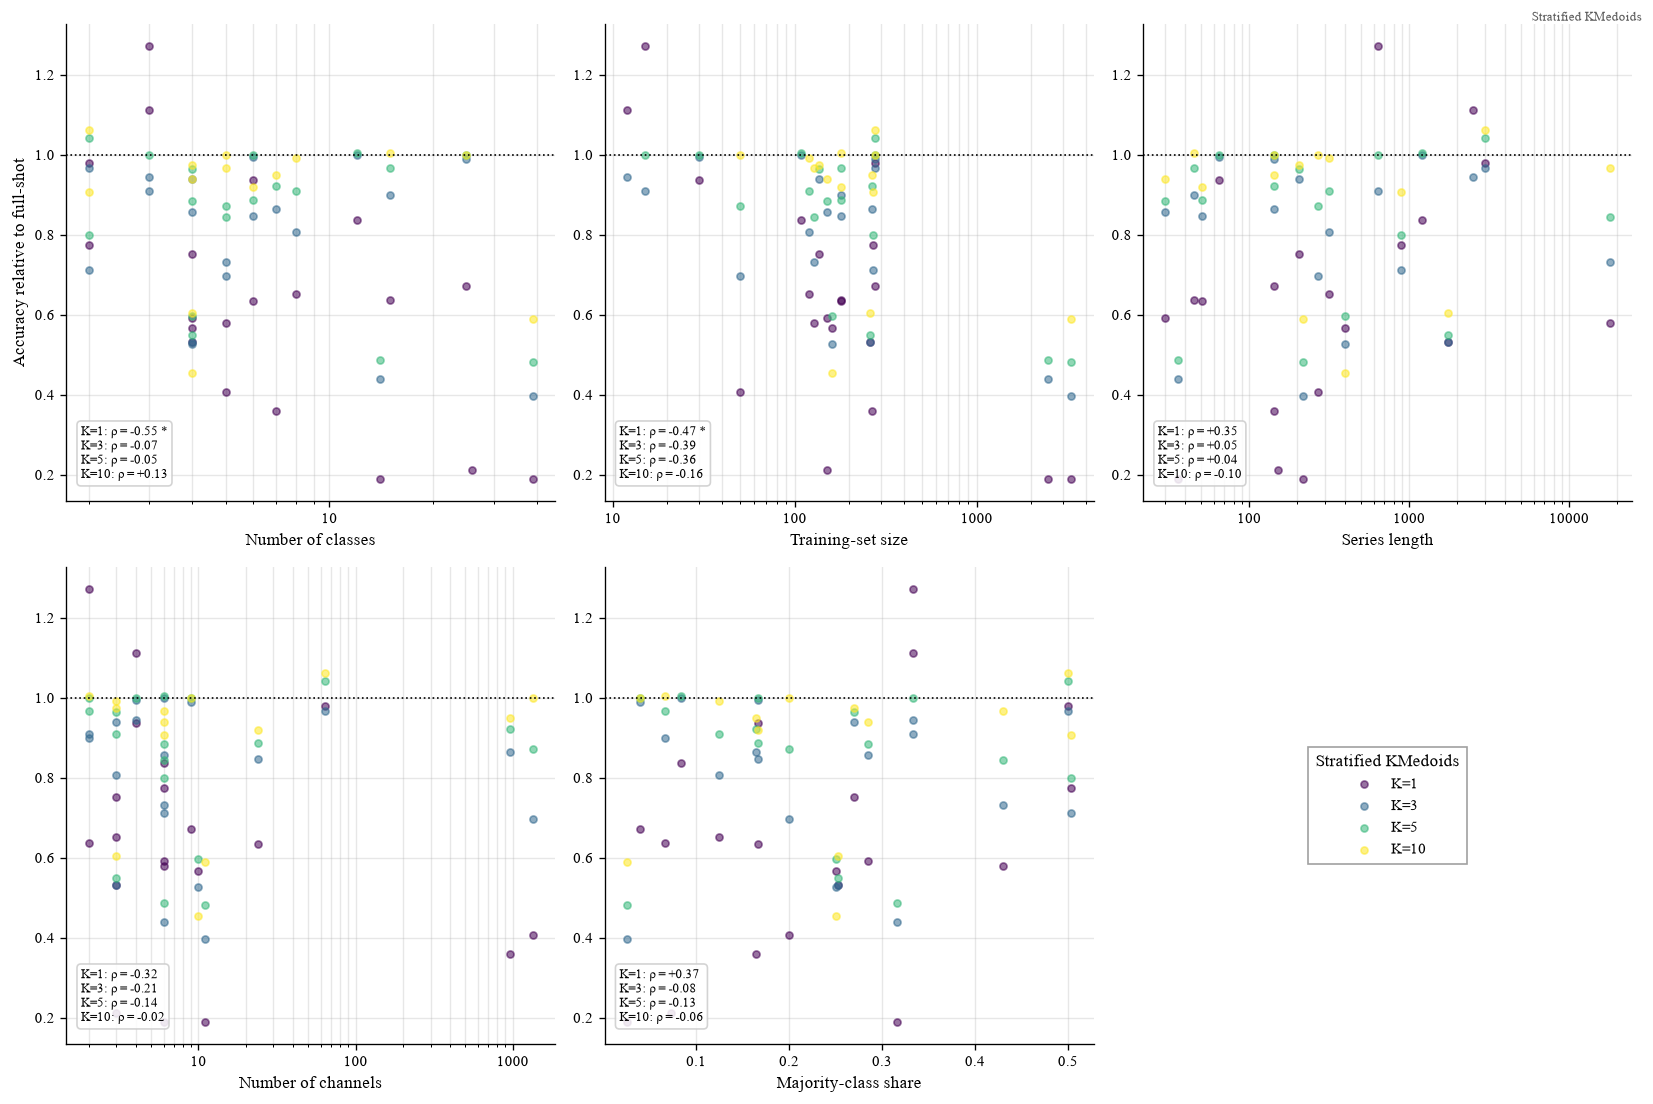

In [52]:
plot_properties_few("uea")

### Few-shot baselines: Ridge and 1NN (same support sets, same datasets)

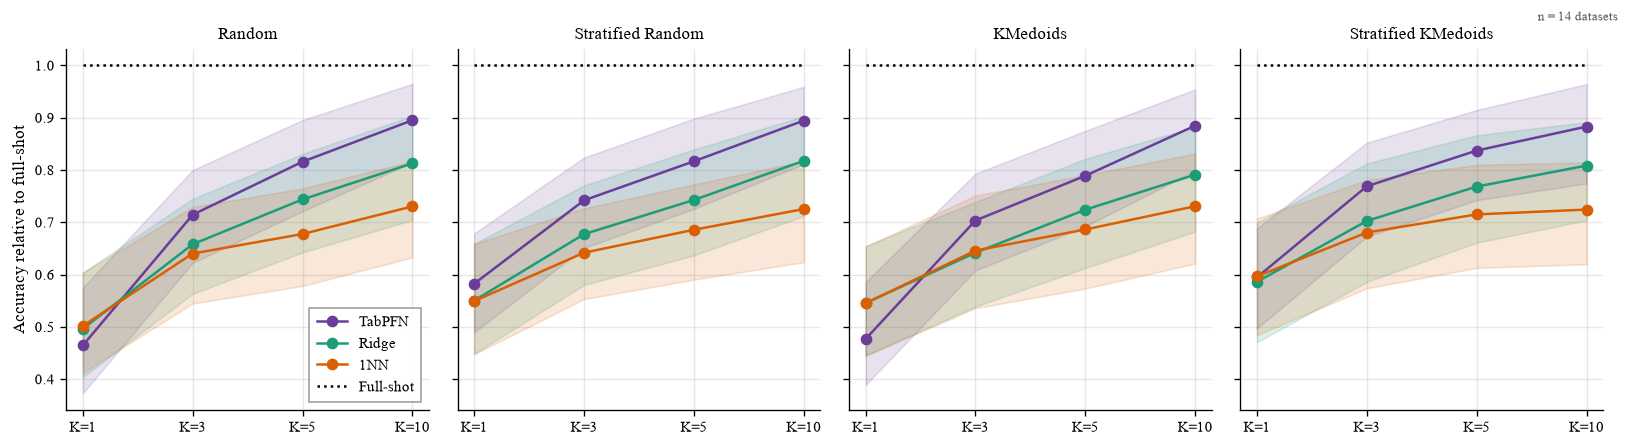

In [53]:
plot_models_vs_k("uea")

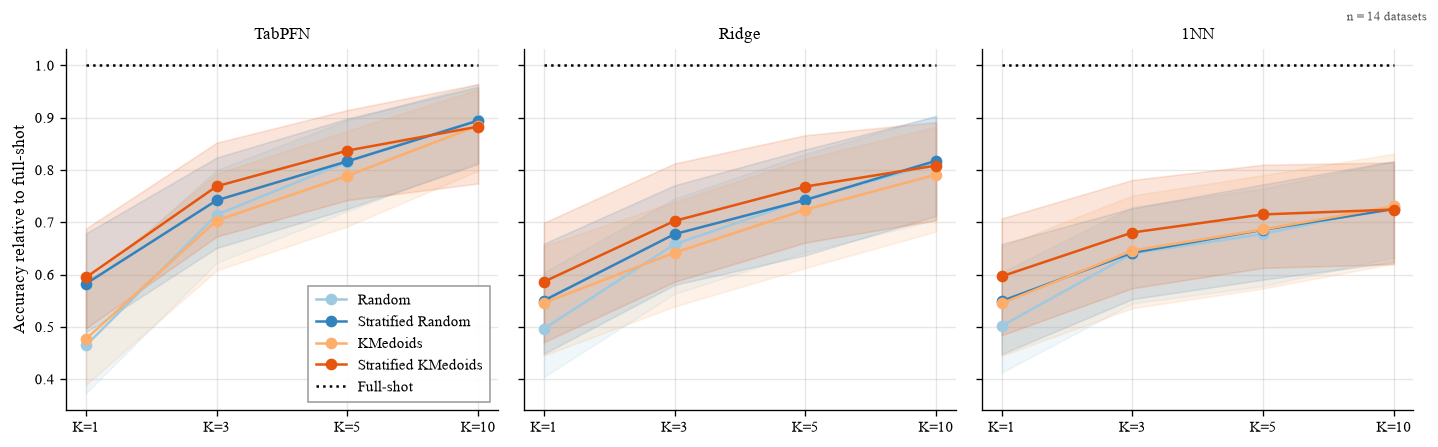

In [54]:
plot_selection_by_model("uea")

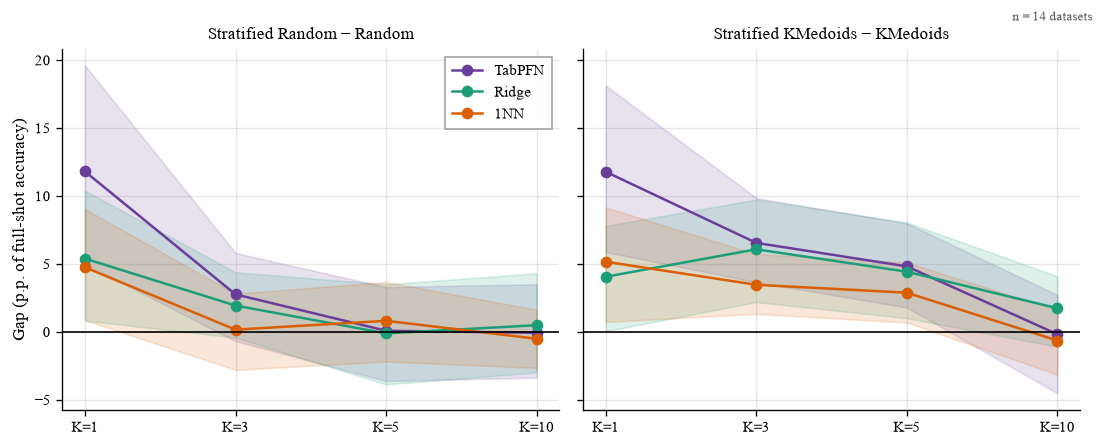

In [55]:
plot_oracle_gap("uea")

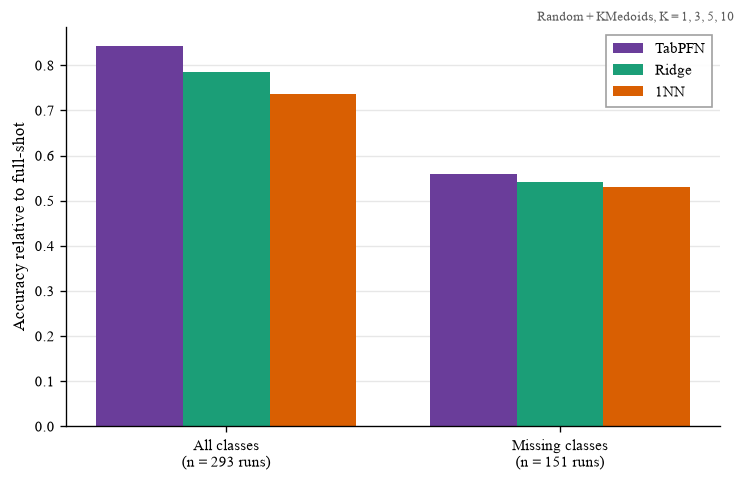

In [56]:
plot_coverage_models("uea")

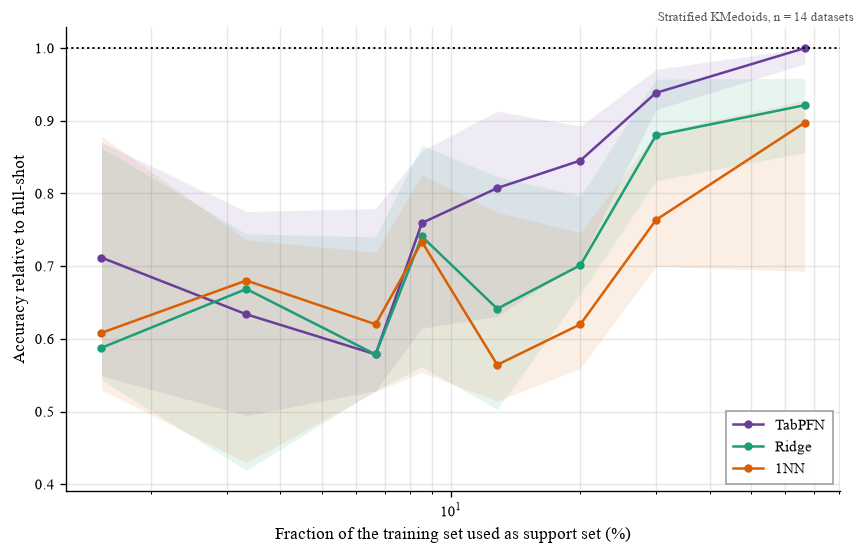

In [57]:
plot_sample_efficiency_models("uea")

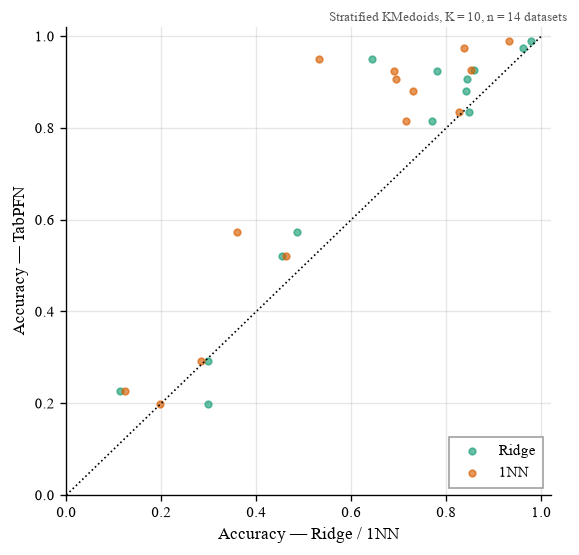

In [58]:
plot_scatter_baselines("uea", "stratified_kmedoids")

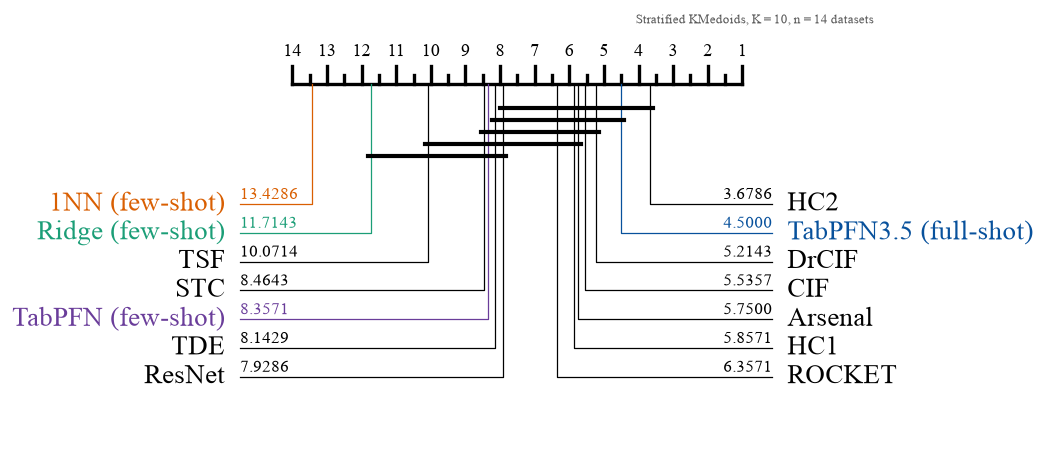

In [59]:
plot_cd_literature_models("uea", "stratified_kmedoids")

# End